# Centromeric heterochromatin of *Capra hircus* — a case study with public data

A single notebook in **three sections**. Everything runs **locally** (macOS) and everything that matters is saved in `data/` as CSV tables.

| Section | What it does | Main output |
|---|---|---|
| **1 · Data and assemblies** | Downloads the T2T-goat2.0 (collapsed), 2.0P and 2.0M genomes (NCBI) and PacBio reads from other breeds (ENA); standardises names | `chromosomes.csv`, `manifest.csv` |
| **2 · Satellites and centromeres** | Orients each chromosome, derives the satellite units with SRF, annotates them and delimits each centromere | **`centromeres_master.csv`** |
| **3 · Statistics and figures** | H1 (scaling), H2 (composition), H3 (homologs) and variation between breeds; reads only the tables in `data/` | results, figures |

**Data source.** Wu et al. 2024 (*Nat Commun* 15:10041): a male Inner Mongolia Cashmere goat (`IMCG_204112`); genomes `GCA_041735815.1` (collapsed), `GCA_041053135.1` (P) and `GCA_040970035.1` (M); reads from BioProject `PRJNA1062519`.

**Design decisions**
- **No CENP-A ChIP-seq.** It was evaluated and discarded; the reason is in `docs/NOTE_chipseq_removed.Rmd`. The centromere is delimited by the **density of SatI–III satellites** (an operational definition).
- **Breeds kept** as a secondary, exploratory analysis (section 3.4).
- **Section 3 is self-contained:** it can be run on its own, without repeating sections 1–2, as long as the tables in `data/` exist.

**Limits of the analysis (read them before interpreting the results)**
- The sequence data come from **a single animal** (male `IMCG_204112`); P and M are the two haplotypes of that individual, not two individuals.
- The **centromere** is an operational definition: the SatI–III satellite block with the most sequence. It is a satellite domain, not the functional CENP-A domain, and it may be longer than the figure reported by Wu et al. (0.6–8.51 Mb).
- **SatIII** (a 22-bp motif) is hard to detect and probably underestimated.
- The **X chromosome** has its only satellite block ~7.2 Mb from the end because its short arm (≈ 5 % of its length) contains the pseudoautosomal region shared with the Y; it was verified that this is not a detection or orientation error (section 2.7). Even so, it is a highly influential point in H1 and H2: it has the shortest centromere in the largest chromosome relative to its centromere.

**How to run it.** Open it from the repository root (or from `notebooks/`) with a Python environment that has the packages in `requirements.txt`. External tools: `minimap2` and `samtools` (Homebrew); KMC, SRF and k8 are installed in `tools/` (cell 1.2).

# SECTION 1 · Data and assemblies

## 1.1 · Configuration

In [ ]:
import os, sys, re, gzip, hashlib, subprocess, shutil, json, io, time, shlex, platform
import urllib.request
from pathlib import Path
import numpy as np, pandas as pd, requests

def urlopen_retry(url, tries=6):           # intermittent DNS/network failures: retry with increasing wait
    for k in range(tries):
        try: return urllib.request.urlopen(url, timeout=60)
        except Exception as e:
            if k == tries-1: raise
            time.sleep(10*(k+1))
Q = lambda p: shlex.quote(str(p))          # paths with spaces (e.g. 'Capra hircus') in shell commands

# ---------- parameters ----------
DOWNLOAD_READS  = True      # PacBio reads (subsampled); False to skip them
PACBIO_BASES_GB = 0.5       # Gb of bases to keep per run (~0.17x per breed; ENA delivers ~0.5 MB/s)
WINDOW_MB       = 15        # proximal window per chromosome (centromeres span 0.6–10 Mb)
MAX_GAP         = 500_000   # bp; maximum separation between satellite blocks of the same centromere
KINDS_SAT       = ['SatI','SatII','SatIII']
SEED            = 20241013
THREADS         = os.cpu_count() or 2

# ---------- paths (all relative to the project folder) ----------
BASE  = Path.cwd()
if BASE.name == 'notebooks': BASE = BASE.parent        # allow running from notebooks/
DATA  = BASE/'data'; TAB = DATA                         # tables, raw downloads and reads
RAW, READS, FIG = DATA/'raw_ncbi', DATA/'reads', DATA/'figures'
ROOT  = BASE/'work'; CLEAN = ROOT/'clean'               # renamed FASTA and windows (regenerated in minutes)
TOOLS = BASE/'tools'
for d in (RAW, READS, FIG, CLEAN, TOOLS): d.mkdir(parents=True, exist_ok=True)

# ---------- sources ----------
ASSEMBLIES = {   # label -> (GenBank accession, NCBI name)
    'T2T': ('GCA_041735815.1', 'T2T-goat2.0'),    # collapsed (30 chromosomes + Y)
    'P'  : ('GCA_041053135.1', 'T2T-goat2.0P'),   # paternal haplotype (autosomes + Y)
    'M'  : ('GCA_040970035.1', 'T2T-goat2.0M'),   # maternal haplotype (autosomes + X)
}
ENA_PROJECT = 'PRJNA1062519'   # NCBI/ENA; CNCB mirror: PRJCA022847
print('Project:', BASE); print('Tables :', TAB)

## 1.2 · Tools

In [2]:
# minimap2 and samtools: Homebrew (brew install minimap2 samtools). KMC, SRF and k8 are installed in ./tools (macOS arm64).
for t in ('minimap2', 'samtools'):
    assert shutil.which(t), f'missing {t}: brew install {t}'
KMC, KMC_DUMP = TOOLS/'bin'/'kmc', TOOLS/'bin'/'kmc_dump'
SRF, SRFUTILS, K8 = TOOLS/'srf'/'srf', TOOLS/'srf'/'srfutils.js', TOOLS/'k8'
if not all(p.exists() for p in (KMC, KMC_DUMP, SRF, SRFUTILS, K8)):
    assert platform.system() == 'Darwin' and platform.machine() == 'arm64', 'automatic installation only for macOS arm64'
    script = f'''
set -e; cd {Q(TOOLS)}
curl -sL -o kmc.tgz https://github.com/refresh-bio/KMC/releases/download/v3.2.4/KMC3.2.4.mac.arm64.tar.gz && tar xzf kmc.tgz
mkdir -p srf && curl -sL https://github.com/lh3/srf/archive/refs/heads/master.tar.gz | tar xz -C srf --strip-components=1 && make -C srf > /dev/null
curl -sL -o k8.tbz https://github.com/attractivechaos/k8/releases/download/v1.2/k8-1.2.tar.bz2 && tar xjf k8.tbz && cp k8-1.2/k8-arm64-Darwin k8 && chmod +x k8
rm -rf kmc.tgz k8.tbz k8-1.2
'''
    subprocess.run(['bash', '-c', script], check=True)
for p in (KMC, KMC_DUMP, SRF, SRFUTILS, K8): assert p.exists(), p
print('Tools OK:', {t: shutil.which(t) for t in ('minimap2', 'samtools')}, '+ KMC, SRF, k8 in', TOOLS)

Tools OK: {'minimap2': '/opt/homebrew/bin/minimap2', 'samtools': '/opt/homebrew/bin/samtools'} + KMC, SRF, k8 in <repo>/tools


## 1.3 · Assembly download (NCBI) with MD5 verification
~0.86 GB compressed per assembly. If the file is already there and its MD5 matches, it is not downloaded again.

In [3]:
def ncbi_dir(acc, name):
    n = acc.split('_')[1].split('.')[0]
    return f'https://ftp.ncbi.nlm.nih.gov/genomes/all/GCA/{n[:3]}/{n[3:6]}/{n[6:9]}/{acc}_{name}/'

def md5_file(p, chunk=1<<24):
    h = hashlib.md5()
    with open(p, 'rb') as f:
        while b := f.read(chunk): h.update(b)
    return h.hexdigest()

def fetch(url, dest):
    subprocess.run(['curl', '-sS', '-L', '--retry', '5', '-C', '-', '-o', str(dest), url], check=True)

manifest = []   # (type, id, file, bytes, md5, source)
for hap, (acc, name) in ASSEMBLIES.items():
    base = ncbi_dir(acc, name); stem = f'{acc}_{name}'
    md5s = {l.split()[1].lstrip('./'): l.split()[0] for l in urlopen_retry(base + 'md5checksums.txt').read().decode().splitlines() if l.strip()}
    fa_gz = RAW/(stem + '_genomic.fna.gz')
    if not (fa_gz.exists() and md5_file(fa_gz) == md5s[stem + '_genomic.fna.gz']):   # already downloaded and intact: not repeated
        fetch(base + stem + '_genomic.fna.gz', fa_gz)
    fetch(base + stem + '_assembly_report.txt', RAW/(stem + '_assembly_report.txt'))
    got = md5_file(fa_gz)
    assert got == md5s[stem + '_genomic.fna.gz'], f'MD5 mismatch in {hap}'
    manifest.append(('assembly', hap, stem + '_genomic.fna.gz', (RAW/(stem+'_genomic.fna.gz')).stat().st_size, got, base))
    print(hap, name, 'OK  MD5', got)

T2T T2T-goat2.0 OK  MD5 87c5212a7acb095d1d9358c67e3c952e


P T2T-goat2.0P OK  MD5 9e4880b5d6ecd19ac677b400f17eaec6


M T2T-goat2.0M OK  MD5 b5c25a68070fff3eec4f5258a2534546


## 1.4 · Chromosome table and renaming
- Names are taken from the NCBI *sequence report* and standardised to `CHI1…CHI29`, `CHIX`, `CHIY`.
- In 2.0M the X chromosome appears in NCBI as `30` (144.69 Mb, identical to the X of T2T-goat2.0): it is renamed `X`.
- 2.0P and 2.0M have all 30 chromosomes but with *gaps* (41 and 36 contigs): they are detected in section 2.

In [4]:
import pandas as pd
def sequence_report(acc):
    rows, token = [], None
    while True:
        u = f'https://api.ncbi.nlm.nih.gov/datasets/v2/genome/accession/{acc}/sequence_reports?page_size=1000' + (f'&page_token={token}' if token else '')
        d = json.load(urlopen_retry(u)); rows += d['reports']; token = d.get('next_page_token')
        if not token: return rows

chrom_rows = []
for hap, (acc, name) in ASSEMBLIES.items():
    for r in sequence_report(acc):
        chrom_rows.append(dict(hap=hap, assembly=name, accession=r['genbank_accession'], ncbi_name=r.get('chr_name'),
                               role=r.get('role'), length=r['length'], gc_percent=r.get('gc_percent')))
chroms = pd.DataFrame(chrom_rows)
chroms['placed'] = chroms.role.eq('assembled-molecule') & chroms.ncbi_name.notna()
# 2.0M names the X as '30': detected by its length, identical to the X of T2T-goat2.0
x_len = chroms[(chroms.hap=='T2T') & (chroms.ncbi_name=='X')].length.iloc[0]
fix = chroms.placed & chroms.ncbi_name.str.fullmatch(r'\d+').fillna(False) & (chroms.length==x_len)
chroms.loc[fix, 'ncbi_name'] = 'X'
chroms['chr'] = chroms.apply(lambda r: f'CHI{r.ncbi_name}' if r.placed else None, axis=1)
chroms['seqname'] = chroms.apply(lambda r: f'{r.hap}_{r.chr}' if r.placed else f'{r.hap}_unplaced_{r.accession}', axis=1)
chroms['kind'] = chroms.chr.map(lambda c: None if c is None else ('X' if c=='CHIX' else 'Y' if c=='CHIY' else 'autosome'))

print(chroms.groupby(['hap','placed']).agg(n=('length','size'), Mb=('length', lambda s: round(s.sum()/1e6,1))).unstack())
# expected checks according to the paper
for hap, g in chroms[chroms.placed].groupby('hap'):
    au = (g.kind=='autosome').sum()
    print(hap, 'autosomes:', au, '| X:', (g.kind=='X').sum(), '| Y:', (g.kind=='Y').sum())
    assert au == 29, 'expected 29 autosomes'
    assert (g.kind=='X').sum() == (hap in ('T2T','M')) and (g.kind=='Y').sum() == (hap in ('T2T','P')), 'unexpected X/Y'
chroms.to_csv(TAB/'chromosomes.csv', index=False)
chroms[chroms.placed].head(3)

          n      Mb
placed True    True
hap                
M        30  2805.1
P        30  2709.9
T2T      31  2863.9
M autosomes: 29 | X: 1 | Y: 0
P autosomes: 29 | X: 0 | Y: 1
T2T autosomes: 29 | X: 1 | Y: 1


,hap,assembly,accession,ncbi_name,role,length,gc_percent,placed,chr,seqname,kind
0,T2T,T2T-goat2.0,CP168611.1,1,assembled-molecule,166528736,41.0,True,CHI1,T2T_CHI1,autosome
1,T2T,T2T-goat2.0,CP168612.1,2,assembled-molecule,147555794,42.0,True,CHI2,T2T_CHI2,autosome
2,T2T,T2T-goat2.0,CP168613.1,3,assembled-molecule,132669774,43.0,True,CHI3,T2T_CHI3,autosome


In [5]:
# Rename FASTA records: >{hap}_CHI{n}; unplaced sequences keep their accession. Indexed with samtools faidx.
def rename_fasta(hap):
    acc, name = ASSEMBLIES[hap]
    mp = chroms[chroms.hap==hap].set_index('accession').seqname.to_dict()
    src = RAW/f'{acc}_{name}_genomic.fna.gz'; out = CLEAN/f'{hap}.fa'
    if Path(str(out)+'.fai').exists(): return out      # already generated
    seen = set()
    with gzip.open(src, 'rt') as fi, open(out, 'w') as fo:
        for line in fi:
            if line.startswith('>'):
                a = line[1:].split()[0]; fo.write(f'>{mp[a]}\n'); seen.add(a)
            else:
                fo.write(line.upper())          # no soft-masking: simplifies N and k-mer counting
    assert seen == set(mp), f'{hap}: missing sequences {set(mp)-seen}'
    subprocess.run(['samtools','faidx',str(out)], check=True)
    return out
GENOME = {h: rename_fasta(h) for h in ASSEMBLIES}
for h,p in GENOME.items(): print(h, p, round(p.stat().st_size/1e9,2), 'GB')

T2T <repo>/work/clean/T2T.fa 2.9 GB
P <repo>/work/clean/P.fa 2.74 GB
M <repo>/work/clean/M.fa 2.84 GB


## 1.5 · PacBio reads from other breeds (subsampled)
Boer, Tibetan, Jining gray, Zhongwei, Liaoning and `IMCG_204112` itself: the basis for estimating **between-individual** variation in satellite content (section 3.4).
These are CLR *subreads* (high error, not HiFi): they are good for satellite fractions by mapping, not for resolving arrays.
They are downloaded by *streaming* and cut when the quota is reached (the full file, 50–120 GB each, is not downloaded).

In [6]:
ena = pd.read_csv(f'https://www.ebi.ac.uk/ena/portal/api/filereport?accession={ENA_PROJECT}&result=read_run&fields=run_accession,sample_title,experiment_title,library_strategy,library_name,instrument_platform,read_count,base_count,fastq_ftp,fastq_bytes&format=tsv', sep='\t')
# Cleaning: only PacBio WGS runs with FASTQ files; RNA-seq, ChIP-seq and runs without FASTQ are discarded
runs = ena[ena.fastq_ftp.notna() & (ena.instrument_platform=='PACBIO_SMRT') & (ena.library_strategy=='WGS')].copy()
runs['type'] = 'PacBio'
runs['individual'] = runs.sample_title.str.replace(' for PacBio sequencing','',regex=False)
runs['Gb'] = runs.fastq_bytes.astype(str).str.split(';').map(lambda x: sum(map(float,x))/1e9)
runs = runs[['run_accession','type','individual','instrument_platform','library_strategy','Gb','fastq_ftp']].sort_values(['type','individual']).reset_index(drop=True)
runs.to_csv(TAB/'public_runs.csv', index=False)
display(runs.drop(columns='fastq_ftp'))

,run_accession,type,individual,instrument_platform,library_strategy,Gb
0,SRR29611984,PacBio,Boer goat,PACBIO_SMRT,WGS,52.715141
1,SRR29612035,PacBio,IMCG_204112,PACBIO_SMRT,WGS,117.772901
2,SRR29611983,PacBio,Jining gray goat,PACBIO_SMRT,WGS,75.160629
3,SRR29611982,PacBio,Liaoning cashmere goat,PACBIO_SMRT,WGS,76.010371
4,SRR29612031,PacBio,Tibetan goat,PACBIO_SMRT,WGS,80.914748
5,SRR29612034,PacBio,Zhongwei goat,PACBIO_SMRT,WGS,69.862471


In [7]:
def stream_lines(url):
    r = requests.get(url, stream=True, timeout=60); r.raise_for_status()
    return gzip.GzipFile(fileobj=r.raw)

def subsample_fastq_bases(url, out, max_bases):
    s, tot, n = stream_lines(url), 0, 0
    with gzip.open(str(out) + '.part','wb') as o:
        while tot < max_bases:
            rec = [s.readline() for _ in range(4)]
            if not rec[0]: break
            o.writelines(rec); tot += len(rec[1].strip()); n += 1
    os.replace(str(out) + '.part', out)          # published only when finished: no truncated files
    return n, tot

from concurrent.futures import ThreadPoolExecutor
def with_retry(fn, *a, tries=5):
    for k in range(tries):
        try: return fn(*a)
        except Exception as e:
            print('  retry', k+1, type(e).__name__); time.sleep(5*(k+1))
    raise RuntimeError('download failed after %d attempts' % tries)

def get_run(r):
    url = 'https://' + r.fastq_ftp.split(';')[0]
    out = READS/f'{r.run_accession}_{re.sub(r"[^A-Za-z0-9]+", "_", r.individual)}.subreads.fastq.gz'
    if not out.exists(): print(r.run_accession, r.individual, with_retry(subsample_fastq_bases, url, out, int(PACBIO_BASES_GB*1e9)))
    return r, [out]

if DOWNLOAD_READS:
    # ENA limits ~0.5 MB/s per connection: 4 runs are downloaded in parallel
    with ThreadPoolExecutor(4) as ex:
        for r, files in ex.map(get_run, list(runs.itertuples())):
            for f in files:
                manifest.append(('reads', r.run_accession, f.name, f.stat().st_size, md5_file(f), 'https://www.ebi.ac.uk/ena/browser/view/' + r.run_accession))
else:
    print('DOWNLOAD_READS=False: raw reads are skipped')

## 1.6 · Download manifest

In [8]:
man = pd.DataFrame(manifest, columns=['type','id','file','bytes','md5','source'])
man['download_date'] = pd.Timestamp.now().strftime('%Y-%m-%d')
man.to_csv(TAB/'manifest.csv', index=False)
print(man[['type','id','file']].assign(MB=(man.bytes/1e6).round(1)).to_string(index=False))

    type          id                                                 file    MB
assembly         T2T           GCA_041735815.1_T2T-goat2.0_genomic.fna.gz 864.7
assembly           P          GCA_041053135.1_T2T-goat2.0P_genomic.fna.gz 817.6
assembly           M          GCA_040970035.1_T2T-goat2.0M_genomic.fna.gz 852.6
   reads SRR29611984              SRR29611984_Boer_goat.subreads.fastq.gz 309.7
   reads SRR29612035            SRR29612035_IMCG_204112.subreads.fastq.gz 405.6
   reads SRR29611983       SRR29611983_Jining_gray_goat.subreads.fastq.gz 396.0
   reads SRR29611982 SRR29611982_Liaoning_cashmere_goat.subreads.fastq.gz 366.6
   reads SRR29612031           SRR29612031_Tibetan_goat.subreads.fastq.gz 149.7
   reads SRR29612034          SRR29612034_Zhongwei_goat.subreads.fastq.gz 359.1


# SECTION 2 · Satellites and centromeres

## 2.1 · End windows and *gaps*
The first and last `WINDOW_MB` of each chromosome are extracted (in the autosomes, which are acrocentric, the centromere lies close to one of the ends) and the runs of `N` are annotated.
The **Y** chromosome (metacentric, with its own centromere `CenY`) is set apart from the SatI–III analysis, as in the paper.

In [9]:
from pyfaidx import Fasta
W = WINDOW_MB*1_000_000
def gap_runs(seq, min_len=1):
    return [(m.start(), m.end()) for m in re.finditer(r'N{%d,}' % min_len, seq)]

win_rows, gap_rows = [], []
for hap, path in GENOME.items():
    fa = Fasta(str(path), as_raw=True, sequence_always_upper=True)
    with open(CLEAN/f'{hap}.left{WINDOW_MB}Mb.fa','w') as fl, open(CLEAN/f'{hap}.right{WINDOW_MB}Mb.fa','w') as fr:
        for r in chroms[(chroms.hap==hap) & chroms.placed].itertuples():
            L = r.length; w = min(W, L)
            left, right = fa[r.seqname][0:w], fa[r.seqname][L-w:L]
            fl.write(f'>{r.seqname}:L\n{left}\n'); fr.write(f'>{r.seqname}:R\n{right}\n')
            for s,e in gap_runs(left): gap_rows.append(dict(hap=hap, chr=r.chr, kind=r.kind, start=s, end=e, len=e-s))
            win_rows.append(dict(hap=hap, chr=r.chr, kind=r.kind, length=L,
                                 N_left=left.count('N'), N_right=right.count('N')))
windows = pd.DataFrame(win_rows); gaps = pd.DataFrame(gap_rows)
chrom_qc = windows.merge(gaps.groupby(['hap','chr']).size().rename('gaps_prox').reset_index(), how='left', on=['hap','chr']).fillna({'gaps_prox':0})
print('Chromosomes with gaps in the proximal window (autosomes + X), by haplotype:')
print(chrom_qc[(chrom_qc.gaps_prox>0)&(chrom_qc.kind!='Y')].groupby('hap').chr.apply(list).to_string())
chrom_qc.to_csv(TAB/'qc_windows.csv', index=False)

Chromosomes with gaps in the proximal window (autosomes + X), by haplotype:
hap
M            [CHI2, CHI10, CHI12, CHI20, CHI22, CHI23]
P    [CHI2, CHI4, CHI10, CHI11, CHI17, CHI23, CHI27...


## 2.2 · Satellite reference and orientation
**SatI**: canonical sequence `X57335.1` (*C. hircus* satellite 1.714, 816 bp, the same one cited by Wu et al.).
**Orientation**: the SatI coverage at the left and right end of each chromosome is compared. In the sequence deposited in NCBI (`GCA_041735815.1`), most chromosomes have the SatI block at the **right** end (the description of version 2.0 says that the centromeres of the autosomes lie on the left); nothing is assumed and it is verified instead: the end with more SatI is chosen as **proximal** and, if it is the right one, the window is taken as the reverse complement.

In [10]:
def efetch_fasta(acc):
    u = f'https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi?db=nuccore&id={acc}&rettype=fasta'
    t = urlopen_retry(u).read().decode().strip().splitlines()
    return ''.join(t[1:]).upper()
satI = efetch_fasta('X57335.1'); assert len(satI) == 816, len(satI)
SATREF = TAB/'SatI_X57335.fa'; SATREF.write_text(f'>SatI_X57335.1\n{satI}\n')
print('SatI', len(satI), 'bp  ->', SATREF)

SatI 816 bp  -> <repo>/data/SatI_X57335.fa


In [11]:
# Orientation: SatI coverage at the left vs right end (acrocentric chromosomes, no Y)
import numpy as np
def sati_coverage(fa_path, out_paf):
    with open(out_paf,'w') as fo:
        subprocess.run(['minimap2','-x','asm20','-N','1000000','-f','10000000','-t',str(THREADS),str(fa_path),str(SATREF)], stdout=fo, stderr=subprocess.DEVNULL, check=True)
    cols = ['q','ql','qs','qe','strand','t','tl','ts','te','nm','al','mq']
    df = pd.read_csv(out_paf, sep='\t', header=None, usecols=range(12), names=cols)
    cov = {}
    for t, g in df.groupby('t'):
        iv = sorted(zip(g.ts, g.te)); tot, cs, ce = 0, *iv[0]
        for s,e in iv[1:]:
            if s > ce: tot += ce-cs; cs, ce = s, e
            else: ce = max(ce, e)
        cov[t] = tot + ce - cs
    return cov

orient = []
for hap in GENOME:
    cL = sati_coverage(CLEAN/f'{hap}.left{WINDOW_MB}Mb.fa',  CLEAN/f'{hap}.L.paf')
    cR = sati_coverage(CLEAN/f'{hap}.right{WINDOW_MB}Mb.fa', CLEAN/f'{hap}.R.paf')
    for r in chroms[(chroms.hap==hap)&chroms.placed&(chroms.kind!='Y')].itertuples():
        orient.append(dict(hap=hap, chr=r.chr, satI_left_Mb=cL.get(f'{r.seqname}:L',0)/1e6, satI_right_Mb=cR.get(f'{r.seqname}:R',0)/1e6))
orient = pd.DataFrame(orient); orient['centromere_on_left'] = orient.satI_left_Mb > orient.satI_right_Mb
print(orient.groupby('hap').centromere_on_left.agg(['sum','size']))
bad = orient[~orient.centromere_on_left]
print('Chromosomes with more SatI on the right (to review):', bad[['hap','chr']].values.tolist())
orient.to_csv(TAB/'qc_orientation.csv', index=False)

     sum  size
hap           
M      5    30
P      6    29
T2T    7    30
Chromosomes with more SatI on the right (to review): [['T2T', 'CHI1'], ['T2T', 'CHI4'], ['T2T', 'CHI5'], ['T2T', 'CHI6'], ['T2T', 'CHI7'], ['T2T', 'CHI8'], ['T2T', 'CHI9'], ['T2T', 'CHI10'], ['T2T', 'CHI11'], ['T2T', 'CHI13'], ['T2T', 'CHI14'], ['T2T', 'CHI15'], ['T2T', 'CHI16'], ['T2T', 'CHI17'], ['T2T', 'CHI20'], ['T2T', 'CHI21'], ['T2T', 'CHI23'], ['T2T', 'CHI24'], ['T2T', 'CHI25'], ['T2T', 'CHI26'], ['T2T', 'CHI27'], ['T2T', 'CHI29'], ['T2T', 'CHIX'], ['P', 'CHI1'], ['P', 'CHI2'], ['P', 'CHI3'], ['P', 'CHI4'], ['P', 'CHI5'], ['P', 'CHI6'], ['P', 'CHI7'], ['P', 'CHI8'], ['P', 'CHI9'], ['P', 'CHI10'], ['P', 'CHI11'], ['P', 'CHI13'], ['P', 'CHI15'], ['P', 'CHI16'], ['P', 'CHI17'], ['P', 'CHI20'], ['P', 'CHI21'], ['P', 'CHI23'], ['P', 'CHI24'], ['P', 'CHI26'], ['P', 'CHI27'], ['P', 'CHI28'], ['P', 'CHI29'], ['M', 'CHI1'], ['M', 'CHI4'], ['M', 'CHI5'], ['M', 'CHI6'], ['M', 'CHI7'], ['M', 'CHI8'], ['M', 'CHI9'], [

In [12]:
from Bio.Seq import Seq
side = {(r.hap, r.chr): ('L' if r.satI_left_Mb >= r.satI_right_Mb else 'R') for r in orient.itertuples()}
orient['centromere_side'] = [side[(r.hap, r.chr)] for r in orient.itertuples()]
orient.to_csv(TAB/'qc_orientation.csv', index=False)
print('End carrying the centromere (SatI), by haplotype:'); print(orient.groupby(['hap','centromere_side']).size().unstack(fill_value=0))
PROX = {}
gap_rows = []
for hap, path in GENOME.items():
    fa = Fasta(str(path), as_raw=True, sequence_always_upper=True)
    PROX[hap] = CLEAN/f'{hap}.prox{WINDOW_MB}Mb.fa'
    with open(PROX[hap], 'w') as fo:
        for r in chroms[(chroms.hap==hap) & chroms.placed & (chroms.kind!='Y')].itertuples():
            w = min(W, r.length)
            s = fa[r.seqname][0:w] if side[(hap, r.chr)] == 'L' else str(Seq(fa[r.seqname][r.length-w:r.length]).reverse_complement())
            fo.write(f'>{r.seqname}\n{s}\n')
            for a, b in gap_runs(s): gap_rows.append(dict(hap=hap, chr=r.chr, kind=r.kind, start=a, end=b, len=b-a))
gaps = pd.DataFrame(gap_rows, columns=['hap','chr','kind','start','end','len']); gaps.to_csv(TAB/'proximal_gaps.csv', index=False)
print('Gaps in the oriented proximal window:', gaps.groupby('hap').chr.nunique().to_dict(), 'chromosomes with gaps')

End carrying the centromere (SatI), by haplotype:
centromere_side   L  R
hap                   
M                30  0
P                28  1
T2T              30  0


Gaps in the oriented proximal window: {'M': 6, 'P': 9} chromosomes with gaps


## 2.3 · Satellite units with SRF
**SRF** (*Satellite Repeat Finder*, Heng Li) counts the very frequent 151-bp k-mers (KMC) and assembles them into the repeat unit of each satellite; for higher-order repeats it returns several consecutive copies. It is run on the first 10 Mb of the proximal window of T2T-goat2.0, as in `srf.sh` from the authors' repository.

In [13]:
# SRF on the oriented proximal windows (T2T-goat2.0, autosomes + X) — reproduces centromere_unit_identification/srf.sh
SRFDIR = CLEAN/'srf'; SRFDIR.mkdir(exist_ok=True)
SRF_WINDOW = 10_000_000     # SRF only needs the satellite block
KMC_RAM_GB = 12
STEP_TIMEOUT_MIN = 30       # if a step exceeds this, it is cut and reported (instead of hanging)
fa = Fasta(str(PROX['T2T']), as_raw=True, sequence_always_upper=True)
with open(SRFDIR/'prox.fa','w') as fo:
    for name in fa.keys():
        fo.write(f'>{name.split("_",1)[1]}\n{fa[name][0:SRF_WINDOW]}\n')

steps = [
 ('kmc',   f"{Q(KMC)} -fm -k151 -t{min(THREADS,8)} -m{KMC_RAM_GB} -sm -ci20 -cs1000000 prox.fa count.kmc tmp_dir > /dev/null"),
 ('dump',  f"{Q(KMC_DUMP)} count.kmc count.txt"),
 ('srf',   f"{Q(SRF)} -p prefix count.txt > srf.fa"),
]
subprocess.run(f"cd {Q(SRFDIR)}; rm -rf tmp_dir count.kmc*; mkdir -p tmp_dir", shell=True, check=True)
for name, cmd in steps:
    t0 = time.time()
    try:
        subprocess.run(['bash','-o','pipefail','-c', f'cd {Q(SRFDIR)}; {cmd}'], check=True, timeout=STEP_TIMEOUT_MIN*60)
    except subprocess.TimeoutExpired:
        raise SystemExit(f'Step {name} exceeded {STEP_TIMEOUT_MIN} min; check the size of count.txt / RAM')
    extra = {p: (SRFDIR/p).stat().st_size for p in ('count.txt','srf.fa') if (SRFDIR/p).exists()} if name in ('dump','srf') else ''
    print(f'{name:6s} {time.time()-t0:6.0f} s', extra)
print('SRF units:', sum(1 for l in open(SRFDIR/'srf.fa') if l.startswith('>')))
print(subprocess.check_output(f"grep '>' {Q(SRFDIR/'srf.fa')} | head -30", shell=True, text=True))

*********************

******
Stage 1: 100%


Stage 2: 95%

Stage 2: 100%


kmc         5 s 
dump        0 s {'count.txt': 172801142}


[M::main] read 1114155 distinct k-mers


srf         1 s {'count.txt': 172801142, 'srf.fa': 28997}
SRF units: 21
>prefix#circ1-6 min=35912,max=36104,avg=35979
>prefix#circ2-1406 min=2763,max=10644,avg=5413
>prefix#circ3-6 min=2332,max=2339,avg=2336
>prefix#circ4-132 min=617,max=1513,avg=919
>prefix#circ5-132 min=177,max=1166,avg=490
>prefix#circ6-2115 min=31,max=798,avg=117
>prefix#circ7-3235 min=32,max=732,avg=114
>prefix#circ8-770 min=26,max=531,avg=116
>prefix#circ9-4067 min=91,max=336,avg=198
>prefix#circ10-816 min=43,max=259,avg=88
>prefix#circ11-4080 min=38,max=230,avg=99
>prefix#circ12-770 min=23,max=171,avg=61
>prefix#circ13-2043 min=41,max=161,avg=124
>prefix#circ14-2459 min=24,max=144,avg=74
>prefix#circ15-2445 min=31,max=116,avg=78
>prefix#circ16-3262 min=25,max=93,avg=54
>prefix#circ17-132 min=20,max=89,avg=65
>prefix#circ18-44 min=34,max=75,avg=52
>prefix#circ19-52 min=34,max=36,avg=35
>prefix#circ20-77 min=21,max=34,avg=22
>prefix#circ21-50 min=20,max=20,avg=20



### Classification of the units into SatI, SatII and SatIII
Rules (by **sequence**, not only by length):
- **SatIII**: the 22-bp motif (`GGAAATCACGTGGGCCCCCAGG` and its variant `GGCAATCACG…`) covers ≥ 60 % of the unit. It includes 44- and 132-bp units, and also larger units (770 and 2115 bp) that are mostly repeats of that motif.
- **SatI**: length a multiple of 816 bp (4 % tolerance; SRF returns higher-order repeats).
- **SatII**: length a multiple of 702 bp (4 % tolerance).
- The rest: `other` (6-bp microsatellites and similar); they are not used.

In [14]:
from Bio import SeqIO
from Bio.Seq import Seq
CORE = 'AATCACGTGGGCCCC'                           # common 15-bp core of the two variants of the 22-bp motif
CORE_RC = str(Seq(CORE).reverse_complement())

def classify_unit(seq):
    s = str(seq).upper(); L = len(s)
    if L >= 22 and min(1, 22*(s.count(CORE) + s.count(CORE_RC))/L) >= 0.6: return 'SatIII'
    for n in range(1, 7):                          # SRF returns HORs: multiples of the monomer
        if abs(L - 816*n) <= 0.04*816*n: return 'SatI'
    for n in range(1, 7):
        if abs(L - 702*n) <= 0.04*702*n: return 'SatII'
    return 'other'

units = pd.DataFrame([dict(id=r.id, length=len(r.seq), family=classify_unit(r.seq)) for r in SeqIO.parse(SRFDIR/'srf.fa', 'fasta')])
print(units.groupby('family').length.agg(['count', 'min', 'max']))
display(units.sort_values(['family', 'length']))
with open(TAB/'satellites_SatI-III.fa', 'w') as fo:
    for rec in SeqIO.parse(SRFDIR/'srf.fa', 'fasta'):
        c = units.set_index('id').loc[rec.id, 'family']
        if c != 'other': fo.write(f'>{c}|{rec.id}\n{rec.seq}\n')
units.to_csv(TAB/'srf_units.csv', index=False)
shutil.copy(SRFDIR/'srf.fa', TAB/'srf.fa')

        count   min   max
family                   
SatI        7   816  4080
SatII       2  1406  2043
SatIII      7    44  2115
other       5     6    77


,id,length,family
9,prefix#circ10-816,816,SatI
14,prefix#circ15-2445,2445,SatI
13,prefix#circ14-2459,2459,SatI
6,prefix#circ7-3235,3235,SatI
15,prefix#circ16-3262,3262,SatI
8,prefix#circ9-4067,4067,SatI
10,prefix#circ11-4080,4080,SatI
1,prefix#circ2-1406,1406,SatII
12,prefix#circ13-2043,2043,SatII
17,prefix#circ18-44,44,SatIII


PosixPath('<repo>/data/srf.fa')

## 2.4 · Satellite annotation in the proximal windows
The SRF units (lengthened with `srfutils enlong`) are used as the **index** and each proximal chromosome as the query with `minimap2` (no base-level alignment, which takes hours on few cores). Each stretch is assigned to the family of the best *hit* (estimated identity) in 100-bp bins, so that families do not overlap. The resolution (~100 bp) is more than enough for centromeres of 0.6–10 Mb.
**Check against the paper:** in T2T-goat2.0 the annotation adds up to ≈ 117 Mb of SatI and ≈ 27 Mb of SatII (Wu et al. report 118.2 and 26.5 Mb). SatIII adds up to only ≈ 6 Mb: the 22-bp motif is poorly detected by alignment.

In [15]:
gaps_df = gaps.copy()      # gaps of the oriented proximal windows (updated if the orientation of any chromosome changes)

In [16]:
ANN = CLEAN/'anot'; ANN.mkdir(exist_ok=True)
def run_bash(s):
    subprocess.run(['bash','-o','pipefail','-c',s], check=True)

run_bash(f"{Q(K8)} {Q(SRFUTILS)} enlong {Q(SRFDIR/'srf.fa')} > {Q(ANN/'units_long.fa')}")
cls_of = units.set_index('id').family.to_dict()
CI = {'SatI':0, 'SatII':1, 'SatIII':2, 'other':3}; CN = {v:k for k,v in CI.items()}
BINA = 100

def annotate(fa_path, tag):
    # units = index, chromosomes = query; each 100-bp stretch is assigned to the best hit (no overlap between families)
    paf = ANN/f'{tag}.paf'; t0 = time.time()
    run_bash(f"minimap2 -N 1000000 -f 1000 -r 100,100 -t {THREADS} {Q(ANN/'units_long.fa')} {Q(fa_path)} > {Q(paf)} 2>/dev/null")
    df = pd.read_csv(paf, sep='\t', header=None, usecols=[0,1,2,3,5,9,10], names=['q','ql','qs','qe','t','nm','bl'])
    df['ci'] = df.t.map(cls_of).fillna('other').map(CI); df['idn'] = df.nm/df.bl
    df = df.sort_values('idn', ascending=False)
    rows = []
    for q, g in df.groupby('q'):
        arr = np.full(int(g.ql.iloc[0]//BINA) + 1, -1, np.int8)
        for s_, e_, c_ in zip((g.qs//BINA).to_numpy(), ((g.qe-1)//BINA + 1).to_numpy(), g.ci.to_numpy()):
            seg = arr[s_:e_]; seg[seg < 0] = c_
        cut = np.flatnonzero(np.diff(np.r_[-2, arr, -2]))
        for a_, b_ in zip(cut[:-1], cut[1:]):
            if arr[a_] >= 0:
                hap_, chr_ = q.split('_', 1)
                rows.append(dict(hap=hap_, chr=chr_, start=int(a_*BINA), end=int(b_*BINA), family=CN[int(arr[a_])], bp=int((b_-a_)*BINA)))
    print(tag, f'{len(df)} hits, {time.time()-t0:.0f} s')
    return pd.DataFrame(rows, columns=['hap','chr','start','end','family','bp'])

ann = pd.concat([annotate(PROX[h], h) for h in GENOME], ignore_index=True)

T2T 1706046 hits, 134 s


P 1456144 hits, 116 s


M 1415424 hits, 124 s


### Orientation review with the complete satellite families
The orientation check (2.2) uses only the SatI reference; a chromosome whose centromere **has no SatI** (e.g. the X) ends up tied at 0 and is assigned to the left side by default. Here the chromosomes with very little satellite in the chosen window are reviewed: the **opposite end** is annotated and, if it clearly has more SatI/II/III, the side is switched.

In [17]:
SAT3 = ['SatI','SatII','SatIII']
sat_tot = ann[ann.family.isin(SAT3)].groupby(['hap','chr']).bp.sum()
chk = chroms[chroms.placed & (chroms.kind != 'Y')][['hap','chr','seqname','length']]
weak = chk[[sat_tot.get((r.hap, r.chr), 0) < 500_000 for r in chk.itertuples()]]
print('Chromosomes with <500 kb of satellite in the chosen window:', weak[['hap','chr']].values.tolist())
side_now = {(r.hap, r.chr): r.centromere_side for r in orient.itertuples()}
swapped, alt_tables = [], []
for hap in weak.hap.unique():
    faG = Fasta(str(GENOME[hap]), as_raw=True, sequence_always_upper=True)
    altp = ANN/f'{hap}.alt.fa'; altseq = {}
    with open(altp, 'w') as fo:
        for r in weak[weak.hap == hap].itertuples():
            w = min(W, r.length)
            s = str(Seq(faG[r.seqname][r.length-w:r.length]).reverse_complement()) if side_now[(hap, r.chr)] == 'L' else faG[r.seqname][0:w]
            altseq[r.chr] = s; fo.write(f'>{r.seqname}\n{s}\n')
    alt = annotate(altp, f'{hap}.alt')
    alt_sat = alt[alt.family.isin(SAT3)].groupby('chr').bp.sum()
    for r in weak[weak.hap == hap].itertuples():
        a_alt, a_cur = alt_sat.get(r.chr, 0), sat_tot.get((hap, r.chr), 0)
        if a_alt >= 200_000 and a_alt > 2*a_cur:           # the other end clearly carries the centromere
            ann = pd.concat([ann[~((ann.hap == hap) & (ann.chr == r.chr))], alt[alt.chr == r.chr]], ignore_index=True)
            gaps_df = gaps_df[~((gaps_df.hap == hap) & (gaps_df.chr == r.chr))]
            gaps_df = pd.concat([gaps_df, pd.DataFrame([dict(hap=hap, chr=r.chr, kind='X' if r.chr=='CHIX' else 'autosome', start=a, end=b, len=b-a) for a, b in gap_runs(altseq[r.chr])])], ignore_index=True)
            swapped.append((hap, r.chr, int(a_cur), int(a_alt)))
print('Switched sides (hap, chromosome, satellite bp before, after):', swapped)
still = [(r.hap, r.chr) for r in weak.itertuples() if (r.hap, r.chr) not in {(s[0], s[1]) for s in swapped}]
print('Still with little satellite (short centromere or no SatI–III):', still)
for h_, c_, *_ in swapped:                               # the orientation of those chromosomes changed
    m_ = (orient.hap == h_) & (orient.chr == c_)
    orient.loc[m_, 'centromere_side'] = orient.loc[m_, 'centromere_side'].map({'L': 'R', 'R': 'L'})
orient.to_csv(TAB/'qc_orientation.csv', index=False)
gaps_df.to_csv(TAB/'proximal_gaps.csv', index=False)
ann.to_csv(TAB/'satellite_annotation.csv', index=False)
print(ann.groupby(['hap','family']).bp.sum().unstack().div(1e6).round(2))

Chromosomes with <500 kb of satellite in the chosen window: [['P', 'CHI3'], ['P', 'CHI28'], ['M', 'CHI7'], ['M', 'CHI21'], ['M', 'CHI29']]


P.alt 71734 hits, 28 s


M.alt 7241 hits, 1 s
Switched sides (hap, chromosome, satellite bp before, after): [('P', 'CHI3', 1100, 6615000)]
Still with little satellite (short centromere or no SatI–III): [('P', 'CHI28'), ('M', 'CHI7'), ('M', 'CHI21'), ('M', 'CHI29')]
family    SatI  SatII  SatIII  other
hap                                 
M       100.79  19.10    4.90   0.26
P       109.35  24.71    7.34   0.29
T2T     117.28  26.68    6.35   0.35


## 2.5 · Centromere delimitation per chromosome
Operational definition (reproducible): the centromere is the **SatI–III satellite block with the most sequence** in the proximal window, merging intervals separated by less than `MAX_GAP` (500 kb). Centromere length = end − start of the block; the satellite content of each family is also summed.
A centromere is flagged **incomplete** if there is a *gap* (N) within 100 kb of the block or if it is shorter than 250 kb (centromere not detected). The Y chromosome is excluded.
**Scope:** this is the whole satellite domain, not the CENP-A domain; that is why it can exceed the range of Wu et al. (here 0.85–10.4 Mb; the shortest is the X). On the X the main block (≈ 0.6 Mb of SatII with almost no SatI) lies ~7.2 Mb from the end: that stretch is the short arm (with the pseudoautosomal region), verified in 2.7.

In [18]:
def centromere_block(a):
    # satellite blocks separated by < MAX_GAP; the centromere is the block with the MOST satellite (not the first one:
    # on the X there is a SatIII remnant near the end and the real block lies further in)
    a = a.sort_values('start'); blocks, cur = [], None
    for r in a.itertuples():
        if cur is None: cur = [r.start, r.end, r.bp]
        elif r.start - cur[1] <= MAX_GAP: cur[1] = max(cur[1], r.end); cur[2] += r.bp
        else: blocks.append(cur); cur = [r.start, r.end, r.bp]
    blocks.append(cur); b = max(blocks, key=lambda x: x[2])
    return int(b[0]), int(b[1])

rows = []
sat_ann = ann[ann.family.isin(KINDS_SAT)]
for r in chroms[chroms.placed & (chroms.kind != 'Y')].itertuples():
    a = sat_ann[(sat_ann.hap == r.hap) & (sat_ann.chr == r.chr)]
    if a.empty:
        rows.append(dict(hap=r.hap, chr=r.chr, kind=r.kind, length=r.length, cen_start=np.nan, cen_end=np.nan, cen_len=np.nan)); continue
    s, e = centromere_block(a)
    inside = a[(a.start >= s) & (a.end <= e)]
    d = dict(hap=r.hap, chr=r.chr, kind=r.kind, length=r.length, cen_start=s, cen_end=e, cen_len=e - s)
    d.update({k: int(inside[inside.family == k].bp.sum()) for k in KINDS_SAT})
    g = gaps_df[(gaps_df.hap == r.hap) & (gaps_df.chr == r.chr)]
    d['n_gaps_cen'] = int(((g.start < e + 100_000) & (g.end > max(0, s - 100_000))).sum()) if len(g) else 0
    rows.append(d)
cen = pd.DataFrame(rows)
cen['complete'] = cen.n_gaps_cen.eq(0) & cen.cen_len.notna() & (cen.cen_len >= 250_000)   # <250 kb = centromere not detected
cen['sat_bp'] = cen[KINDS_SAT].sum(axis=1)
cen.to_csv(TAB/'centromeres.csv', index=False)

T = cen[cen.hap == 'T2T']
print('T2T-goat2.0 · centromere length (Mb): min %.2f (%s) · max %.2f (%s) · median %.2f' % (
      T.cen_len.min()/1e6, T.loc[T.cen_len.idxmin(),'chr'], T.cen_len.max()/1e6, T.loc[T.cen_len.idxmax(),'chr'], T.cen_len.median()/1e6))
print('Expected (Wu et al. 2024): 0.6–8.51 Mb, shortest on X. SatI ≈ 67.81 % of the centromeres.')
print('SatI / sum of centromeric blocks: %.1f %%' % (100*T.SatI.sum()/T.cen_len.sum()))
print('Incomplete centromeres by haplotype:', cen.groupby('hap').complete.apply(lambda s: int((~s).sum())).to_dict(), '(paper: ~9 in P, ~6 in M)')
cen[cen.hap=='T2T'].head()

T2T-goat2.0 · centromere length (Mb): min 0.85 (CHIX) · max 10.38 (CHI16) · median 7.14
Expected (Wu et al. 2024): 0.6–8.51 Mb, shortest on X. SatI ≈ 67.81 % of the centromeres.
SatI / sum of centromeric blocks: 55.5 %
Incomplete centromeres by haplotype: {'M': 5, 'P': 9, 'T2T': 0} (paper: ~9 in P, ~6 in M)


,hap,chr,kind,length,cen_start,cen_end,cen_len,SatI,SatII,SatIII,n_gaps_cen,complete,sat_bp
0,T2T,CHI1,autosome,166528736,27200,9191300,9164100,5727200,970100,365600,0,True,7062900
1,T2T,CHI2,autosome,147555794,31600,10257700,10226100,6489800,1049500,330800,0,True,7870100
2,T2T,CHI3,autosome,132669774,33300,8881400,8848100,4763300,863600,602900,0,True,6229800
3,T2T,CHI4,autosome,126865584,28400,5185600,5157200,2918100,1286500,0,0,True,4204600
4,T2T,CHI5,autosome,127915634,28900,7786700,7757800,2713700,963000,253400,0,True,3930100


## 2.6 · Master table
A single table with everything needed for section 3 (one row per chromosome and haplotype).

| Column | Meaning |
|---|---|
| `hap`, `chr`, `kind` | haplotype (T2T, P, M), chromosome (`CHI1`…`CHIX`) and type (autosome / X) |
| `length` | chromosome length (bp) |
| `cen_start`, `cen_end`, `cen_len` | start, end and length of the centromeric block in the oriented proximal window (bp) |
| `SatI`, `SatII`, `SatIII`, `sat_bp` | bp of each family within the block, and total |
| `n_gaps_cen`, `complete` | *gaps* near the centromere and whether it is considered complete |
| `centromere_side` | end of the chromosome where the centromere is (`L` or `R`) |
| `cen_Mb`, `sat_Mb`, `rest_Mb` | length of the centromere, of the satellite and of the rest of the chromosome (Mb) |
| `prop_SatI`…`prop_SatIII` | proportion of each family over the satellite of the block |

In [19]:
master = cen.merge(orient[['hap', 'chr', 'centromere_side']], on=['hap', 'chr'], how='left')
master['cen_Mb']  = master.cen_len/1e6
master['sat_Mb']  = master.sat_bp/1e6
master['rest_Mb'] = (master.length - master.cen_len)/1e6
for k in KINDS_SAT: master['prop_'+k] = master[k]/master.sat_bp.replace(0, np.nan)
master.to_csv(TAB/'centromeres_master.csv', index=False)
print(master.shape, '→', TAB/'centromeres_master.csv')
master[master.hap == 'T2T'].round(3).head()

(89, 20) → <repo>/data/centromeres_master.csv


,hap,chr,kind,length,cen_start,cen_end,cen_len,SatI,SatII,SatIII,n_gaps_cen,complete,sat_bp,centromere_side,cen_Mb,sat_Mb,rest_Mb,prop_SatI,prop_SatII,prop_SatIII
0,T2T,CHI1,autosome,166528736,27200,9191300,9164100,5727200,970100,365600,0,True,7062900,L,9.164,7.063,157.365,0.811,0.137,0.052
1,T2T,CHI2,autosome,147555794,31600,10257700,10226100,6489800,1049500,330800,0,True,7870100,L,10.226,7.870,137.330,0.825,0.133,0.042
2,T2T,CHI3,autosome,132669774,33300,8881400,8848100,4763300,863600,602900,0,True,6229800,L,8.848,6.230,123.822,0.765,0.139,0.097
3,T2T,CHI4,autosome,126865584,28400,5185600,5157200,2918100,1286500,0,0,True,4204600,L,5.157,4.205,121.708,0.694,0.306,0.000
4,T2T,CHI5,autosome,127915634,28900,7786700,7757800,2713700,963000,253400,0,True,3930100,L,7.758,3.930,120.158,0.690,0.245,0.064


## 2.7 · Verification of the X chromosome
The X has the shortest centromere (≈ 0.85 Mb), and its satellite block lies ~7.2 Mb from the end, not ~30 kb as in the autosomes. Before using it in the analysis, it is checked whether this is real or a detection, orientation or assembly error.

**What the literature says.** The X of *C. hircus* is **acrocentric** (Hansen 2009; Kowal-Mierzwa et al. 2026; Wu et al. 2024); some morphometric measurements place it as subtelocentric (Putri et al. 2018). Wu et al. describe a **pseudoautosomal region (PAR) of ~7 Mb on the short arms of the X and the Y**.

**Checks (T2T-goat2.0):**
1. **PAR:** are the first ~7 Mb of the X homologous to the Y?
2. **Genes:** gene density of the short arm compared with the rest of the X (NCBI annotation).
3. **Whole X:** are there other satellite blocks? Does SRF applied to the whole X find units that were not there?
4. **Orientation:** is the X of haplotype M collinear with the X of T2T-goat2.0?

In [20]:
XDIR = CLEAN/'xcheck'; XDIR.mkdir(exist_ok=True)
def faidx(genome, name, out): subprocess.run(f"samtools faidx {Q(genome)} {name} > {Q(out)}", shell=True, check=True)
faidx(GENOME['T2T'], 'T2T_CHIX', XDIR/'X.fa'); faidx(GENOME['T2T'], 'T2T_CHIY', XDIR/'Y.fa'); faidx(GENOME['M'], 'M_CHIX', XDIR/'MX.fa')
paf_cols = ['q', 'ql', 'qs', 'qe', 'strand', 't', 'tl', 'ts', 'te', 'nm', 'al', 'mq']
def paf_table(args, out):
    run_bash(f"minimap2 {args} -t {THREADS} > {Q(out)} 2>/dev/null")
    return pd.read_csv(out, sep='\t', header=None, usecols=range(12), names=paf_cols)

subprocess.run(['samtools', 'faidx', str(XDIR/'X.fa')], check=True)
xlen = int(open(str(XDIR/'X.fa') + '.fai').read().split('\t')[1])
# 1) PAR: the longest alignment of the X against the Y
xy = paf_table(f"-x asm10 {Q(XDIR/'Y.fa')} {Q(XDIR/'X.fa')}", XDIR/'X_vs_Y.paf'); par = xy.sort_values('al', ascending=False).iloc[0]
print(f'PAR: X {par.qs/1e6:.3f}–{par.qe/1e6:.3f} Mb  ↔  Y {par.ts/1e6:.3f}–{par.te/1e6:.3f} Mb · strand {par.strand} · identity ≈ {par.nm/par.al:.2f} · {par.al/1e6:.2f} Mb')
# 4) collinearity of the X of haplotype M with the X of T2T
mx = paf_table(f"-x asm5 {Q(XDIR/'X.fa')} {Q(XDIR/'MX.fa')}", XDIR/'MX_vs_X.paf'); mb = mx.sort_values('al', ascending=False).iloc[0]
print(f'X(M) vs X(T2T): main block {mb.al/1e6:.2f} Mb of {mb.ql/1e6:.2f} Mb, strand {mb.strand}, coordinates {mb.qs/1e6:.2f}–{mb.qe/1e6:.2f} ↔ {mb.ts/1e6:.2f}–{mb.te/1e6:.2f} Mb')

# 2) genes on the X (NCBI annotation)
gff = RAW/'GCA_041735815.1_T2T-goat2.0_genomic.gff.gz'
if not gff.exists():
    fetch(ncbi_dir(*ASSEMBLIES['T2T']) + 'GCA_041735815.1_T2T-goat2.0_genomic.gff.gz', gff)
xacc = chroms[(chroms.hap == 'T2T') & (chroms.chr == 'CHIX')].accession.iloc[0]
gm = []
with gzip.open(gff, 'rt') as f:
    for l in f:
        c = l.rstrip('\n').split('\t')
        if len(c) > 8 and c[0] == xacc and c[2] == 'gene': gm.append((int(c[3]) + int(c[4]))/2e6)
gm = np.array(gm); xmb = xlen/1e6
print(f'Genes on the X: {len(gm)} ({len(gm)/xmb:.1f}/Mb) · in the first 7 Mb (short arm): {int((gm < 7).sum())} ({(gm < 7).sum()/7:.1f}/Mb)')

PAR: X 0.012–7.040 Mb  ↔  Y 0.019–7.020 Mb · strand + · identity ≈ 0.89 · 7.07 Mb


X(M) vs X(T2T): main block 144.68 Mb of 144.69 Mb, strand +, coordinates 0.01–144.69 ↔ 0.01–144.69 Mb


Genes on the X: 1226 (8.5/Mb) · in the first 7 Mb (short arm): 62 (8.9/Mb)


In [21]:
# 3) the whole X: satellite blocks and SRF applied to the X alone
axs = annotate(XDIR/'X.fa', 'X_full'); axs = axs[axs.family.isin(KINDS_SAT)].sort_values('start')
blocks, cur = [], None
for r in axs.itertuples():
    if cur is not None and r.start - cur[1] <= 20_000: cur[1] = max(cur[1], r.end); cur[2] += r.bp
    else:
        if cur: blocks.append(cur)
        cur = [r.start, r.end, r.bp]
blocks.append(cur); blocks = [b for b in blocks if b[1] - b[0] >= 30_000]
print('Satellite blocks ≥ 30 kb along the whole X (Mb):', [(round(a/1e6, 3), round(b/1e6, 3), f'{n/1e3:.0f} kb of satellite') for a, b, n in blocks])
fam = axs.groupby('family').bp.sum().to_dict(); print('Satellite on the whole X (bp):', fam)

SX = XDIR/'srf'; SX.mkdir(exist_ok=True); subprocess.run(f"rm -rf {Q(SX)}/tmp; mkdir -p {Q(SX)}/tmp", shell=True, check=True)
run_bash(f"cd {Q(SX)} && {Q(KMC)} -fm -k151 -t{min(THREADS, 8)} -m{KMC_RAM_GB} -sm -ci20 -cs1000000 {Q(XDIR/'X.fa')} count.kmc tmp > /dev/null && {Q(KMC_DUMP)} count.kmc count.txt && {Q(SRF)} -p xs count.txt > srf_X.fa 2> /dev/null")
ux = [(r.id, len(r.seq)) for r in SeqIO.parse(SX/'srf_X.fa', 'fasta')]
print('Units that SRF finds when analysing the X alone:', ux)

blk = max(blocks, key=lambda b: b[2]); p_arm = blk[0]
check_x = pd.DataFrame([dict(
    X_length_bp=xlen, block_start_bp=blk[0], block_end_bp=blk[1], block_satellite_bp=int(blk[2]), fraction_from_end=blk[0]/xlen,
    satellite_blocks_ge30kb=len(blocks), SRF_units_on_X=len(ux), SatII_bp=int(fam.get('SatII', 0)), SatI_bp=int(fam.get('SatI', 0)), SatIII_bp=int(fam.get('SatIII', 0)),
    PAR_X_start=int(par.qs), PAR_X_end=int(par.qe), PAR_Y_start=int(par.ts), PAR_Y_end=int(par.te), PAR_identity=par.nm/par.al,
    genes_X=len(gm), genes_per_Mb_X=len(gm)/xmb, genes_per_Mb_first7Mb=(gm < 7).sum()/7,
    X_haplotypeM_collinear_bp=int(mb.al), X_haplotypeM_strand=mb.strand)])
check_x.to_csv(TAB/'x_chromosome_check.csv', index=False); display(check_x.T)
print(f'Reading: the only satellite block of the X is {blk[0]/1e6:.2f} Mb from the end ({100*blk[0]/xlen:.1f} % of its length); '
      f'the ~{par.qe/1e6:.1f} Mb short arm is homologous to the Y (PAR) and has a gene density similar to the rest of the X. There is no evidence of a detection or orientation error.')

X_full 3224 hits, 3 s
Satellite blocks ≥ 30 kb along the whole X (Mb): [(7.233, 8.085, '638 kb of satellite')]
Satellite on the whole X (bp): {'SatI': 46800, 'SatII': 592100}


**********
Stage 1: 100%


Stage 2: 100%


Units that SRF finds when analysing the X alone: [('xs#circ1-6', 6), ('xs#circ2-2801', 2801), ('xs#circ3-17', 17), ('xs#circ4-50', 50)]


,0
X_length_bp,144688805
block_start_bp,7232600
block_end_bp,8085400
block_satellite_bp,638500
fraction_from_end,0.049987
satellite_blocks_ge30kb,1
SRF_units_on_X,4
SatII_bp,592100
SatI_bp,46800
SatIII_bp,0


Reading: the only satellite block of the X is 7.23 Mb from the end (5.0 % of its length); the ~7.0 Mb short arm is homologous to the Y (PAR) and has a gene density similar to the rest of the X. There is no evidence of a detection or orientation error.


# SECTION 3 · Statistics and figures

This section **reads only the tables in `data/`** and can be run on its own. All analyses use real data.
> Methods: log–log scaling with an interaction between haplotypes (as in Plačková et al. 2021), pairwise log-ratios for composition (Greenacre et al. 2022) and paired permutation tests for the homologs.

## 3.0 · Configuration and loading of the tables

In [1]:
import os, re, io, gzip, json, subprocess, shlex
from pathlib import Path
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
import statsmodels.api as sm, statsmodels.formula.api as smf
from scipy import stats

Q = lambda p: shlex.quote(str(p))
BASE = Path.cwd()
if BASE.name == 'notebooks': BASE = BASE.parent
TAB = BASE/'data'; READS = TAB/'reads'; FIG = TAB/'figures'; FIG.mkdir(exist_ok=True)
THREADS = os.cpu_count() or 2; SEED = 20241013; KINDS_SAT = ['SatI', 'SatII', 'SatIII']
sat_lib = TAB/'satellites_SatI-III.fa'

cen    = pd.read_csv(TAB/'centromeres_master.csv')
chroms = pd.read_csv(TAB/'chromosomes.csv')
units  = pd.read_csv(TAB/'srf_units.csv')
runs   = pd.read_csv(TAB/'public_runs.csv')
T = cen[cen.hap == 'T2T']
print(len(cen), 'rows (chromosome × haplotype) |', units.family.value_counts().to_dict(), '|', len(runs), 'PacBio runs')
print('T2T: centromere length (Mb) min %.2f (%s) · max %.2f (%s) · median %.2f' % (
      T.cen_len.min()/1e6, T.loc[T.cen_len.idxmin(), 'chr'], T.cen_len.max()/1e6, T.loc[T.cen_len.idxmax(), 'chr'], T.cen_len.median()/1e6))

89 rows (chromosome × haplotype) | {'SatIII': 7, 'SatI': 7, 'other': 5, 'SatII': 2} | 6 PacBio runs
T2T: centromere length (Mb) min 0.85 (CHIX) · max 10.38 (CHI16) · median 7.14


## 3.1 · H1 — Scaling of centromeric heterochromatin (real data)
**Question:** how much does the centromere grow when the chromosome grows?
**Model:** `ln(centromere) = a + b · ln(remaining length)`, with *remaining length* = chromosome length − centromere (this avoids the mathematical coupling of the fraction). `b` is the allometric exponent: `b = 1` isometry, `b < 1` the centromere grows less than proportionally, `b = 0` the centromere does not depend on size.
**Data:** 30 chromosomes of T2T-goat2.0 (29 autosomes + X) of the reference animal.

**What is measured and what the literature leads us to expect.** What is measured is the length of the **satellite array** of the centromeric block, not the size of the *functional* centromere (CENP-A domain or kinetochore). The functional size is physically limited and is associated with genome or chromosome size (Plačková et al. 2021; Wang et al. 2021; Irvine et al. 2004), although **within a species it is rather uniform** (Zhang and Dawe 2012). The satellite array, in contrast, has no such constraint and varies widely between chromosomes, haplotypes and individuals (up to 30-fold in humans; Logsdon et al. 2025; Sullivan et al. 2011; Thakur et al. 2021). A **strong correlation** between array length and chromosome size is therefore **not expected**. The scaling hypothesis is still tested, and the **power** of the analysis is reported, to tell «there is no scaling» apart from «there would be no way to see it».

**What is reported (the main result is the slope with its interval, not the p-value):**
- Two contrasts on the slope: **`b = 0`** (is there scaling?) and `b = 1` against `b < 1` (is it less than proportional?). The latter is almost trivial when `b` is close to 0, so it is not the central criterion.
- Intervals: t with robust errors (HC3) and percentile *bootstrap* of chromosomes (5000 resamples).
- **Influence:** Cook's distance and the slope leaving each chromosome out (the X carries a lot of weight).
- **Sensitivity:** without the X; with pure satellite (`sat_Mb`) as the response; with total length as the predictor; robust regressions (Theil–Sen and Huber); and replication with haplotypes P and M separately.
- **Power:** given the observed dispersion, which true slope the analysis could detect (with and without the X). The result is read together with the interval: ruling out a *strong* scaling is not the same as ruling out a *weak or moderate* one.

In [2]:
D = cen[(cen.hap == 'T2T') & cen.complete & cen.cen_len.notna()].copy()
D['cen_Mb'] = D.cen_len/1e6; D['rest_Mb'] = (D.length - D.cen_len)/1e6
D['lcen'], D['lrest'] = np.log(D.cen_Mb), np.log(D.rest_Mb)
D['lsat'], D['lchr'] = np.log(D.sat_bp/1e6), np.log(D.length/1e6)

rng_h1 = np.random.default_rng(SEED)
def h1_row(df, y, x, label, how='ols'):
    df = df.dropna(subset=[y, x]); X, Y, n = df[x].to_numpy(), df[y].to_numpy(), len(df)
    p0 = p1 = r2 = r2a = np.nan
    if how == 'ols':
        m = smf.ols(f'{y} ~ {x}', df).fit(cov_type='HC3'); b, se = m.params[x], m.bse[x]
        lo, hi = m.conf_int().loc[x]; r2, p0, r2a = m.rsquared, m.pvalues[x], m.rsquared_adj
        p1 = stats.t.cdf((b - 1)/se, m.df_resid)              # H0: b = 1 against b < 1
    elif how == 'theil':
        b, _, lo, hi = stats.theilslopes(Y, X, 0.95)
    else:                                                     # Huber
        m = smf.rlm(f'{y} ~ {x}', df, M=sm.robust.norms.HuberT()).fit(); b = m.params[x]; lo, hi = m.conf_int().loc[x]; p0 = m.pvalues[x]
    idx = rng_h1.integers(0, n, (5000, n)); bs = np.array([np.polyfit(X[i], Y[i], 1)[0] for i in idx])
    rho, prho = stats.spearmanr(X, Y)
    return dict(model=label, n=n, slope=b, CI95=f'[{lo:.2f}, {hi:.2f}]', CI95_boot=f'[{np.percentile(bs, 2.5):.2f}, {np.percentile(bs, 97.5):.2f}]',
                p_slope_0=p0, p_slope_lt_1=p1, R2=r2, R2_adj=r2a, spearman=rho, p_spearman=prho)

def hap_frame(hap):
    d = cen[(cen.hap == hap) & cen.complete & cen.cen_len.notna() & (cen.kind != 'Y')].copy()
    d['lcen'] = np.log(d.cen_len/1e6); d['lrest'] = np.log((d.length - d.cen_len)/1e6); return d

rows = [h1_row(D, 'lcen', 'lrest', 'MAIN · T2T, 29 autosomes + X'),
        h1_row(D[D.kind == 'autosome'], 'lcen', 'lrest', 'without the X'),
        h1_row(D, 'lsat', 'lrest', 'response = pure satellite (sat_Mb)'),
        h1_row(D, 'lcen', 'lchr', 'predictor = total chromosome length'),
        h1_row(D, 'lcen', 'lrest', 'Theil–Sen (robust), with X', 'theil'),
        h1_row(D[D.kind == 'autosome'], 'lcen', 'lrest', 'Theil–Sen (robust), without X', 'theil'),
        h1_row(D, 'lcen', 'lrest', 'Huber (robust), with X', 'huber'),
        h1_row(hap_frame('P'), 'lcen', 'lrest', 'replicate: haplotype P (complete autosomes)'),
        h1_row(hap_frame('M'), 'lcen', 'lrest', 'replicate: haplotype M (complete autosomes + X)')]
h1 = pd.DataFrame(rows)             # the first row is the main result (other cells read it)
h1.to_csv(TAB/'H1_scaling.csv', index=False)
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 60)
display(h1.round(4))

,model,n,slope,CI95,CI95_boot,p_slope_0,p_slope_lt_1,R2,R2_adj,spearman,p_spearman
0,"MAIN · T2T, 29 autosomes + X",30,-0.1166,"[-0.80, 0.57]","[-0.81, 0.38]",0.7384,0.0017,0.0086,-0.0268,0.0705,0.7111
1,without the X,29,0.1884,"[-0.10, 0.47]","[-0.11, 0.44]",0.1930,0.0000,0.0622,0.0275,0.1734,0.3684
2,response = pure satellite (sat_Mb),30,-0.1176,"[-0.79, 0.55]","[-0.81, 0.37]",0.7301,0.0014,0.0089,-0.0265,0.0585,0.7588
3,predictor = total chromosome length,30,-0.0520,"[-0.75, 0.64]","[-0.80, 0.45]",0.8833,0.0030,0.0015,-0.0342,0.1221,0.5203
4,"Theil–Sen (robust), with X",30,0.0216,"[-0.33, 0.38]","[-0.81, 0.38]",NaN,NaN,NaN,NaN,0.0705,0.7111
5,"Theil–Sen (robust), without X",29,0.1093,"[-0.18, 0.46]","[-0.11, 0.44]",NaN,NaN,NaN,NaN,0.1734,0.3684
6,"Huber (robust), with X",30,0.1086,"[-0.18, 0.40]","[-0.82, 0.38]",0.4671,NaN,NaN,NaN,0.0705,0.7111
7,replicate: haplotype P (complete autosomes),20,0.1943,"[-0.11, 0.50]","[-0.18, 0.46]",0.2065,0.0000,0.0352,-0.0184,0.1579,0.5061
8,replicate: haplotype M (complete autosomes + X),25,0.0136,"[-0.87, 0.90]","[-0.81, 0.79]",0.9761,0.0200,0.0001,-0.0434,0.1754,0.4017


In [3]:
# Influence: Cook's distance and the slope leaving each chromosome out (main model)
m_main = smf.ols('lcen ~ lrest', D).fit()
D['cook'] = m_main.get_influence().cooks_distance[0]
D['slope_without_this'] = [np.polyfit(D.lrest.drop(i), D.lcen.drop(i), 1)[0] for i in D.index]
threshold = 4/len(D)
infl = D[D.cook > threshold][['chr', 'kind', 'cen_Mb', 'rest_Mb', 'cook', 'slope_without_this']].sort_values('cook', ascending=False)
print(f'Main slope: {m_main.params["lrest"]:.3f}. Leaving one chromosome out at a time: [{D.slope_without_this.min():.3f}, {D.slope_without_this.max():.3f}]')
print(f'Influential chromosomes (Cook > 4/n = {threshold:.3f}):'); display(infl.round(3))
infl.to_csv(TAB/'H1_influence.csv', index=False)

b0 = h1.iloc[0]
print('\nReading:')
print(f'· Slope = {b0.slope:.2f} (CI95 {b0.CI95}; bootstrap {b0.CI95_boot}); R² = {b0.R2:.3f}.')
print(f'· H0 b = 0: p = {b0.p_slope_0:.3g} → ' + ('no evidence of scaling.' if b0.p_slope_0 > 0.05 else 'evidence of scaling.'))
print(f'· H0 b = 1 vs b < 1: p = {b0.p_slope_lt_1:.3g} (expected when b is close to 0; it is not the central criterion).')

# Interaction (as in Plačková et al. 2021): does the slope differ between haplotypes P and M?
# The two haplotypes come from the same animal, so errors are cluster-robust by chromosome. (X vs autosomes is not estimable: there is a single X.)
pm = pd.concat([hap_frame('P'), hap_frame('M')]); pm = pm[pm.kind == 'autosome'].copy()
mi = smf.ols('lcen ~ lrest * C(hap)', pm).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(pm.chr)[0]})
term = [t for t in mi.params.index if t.startswith('lrest:')][0]
inter = pd.DataFrame([dict(model='lcen ~ lrest * hap (P vs M, complete autosomes)', n=len(pm), slope_P=mi.params['lrest'],
                           slope_diff_M_minus_P=mi.params[term], CI95_diff=f'[{mi.conf_int().loc[term, 0]:.2f}, {mi.conf_int().loc[term, 1]:.2f}]',
                           p_interaction=mi.pvalues[term], R2_adj=mi.rsquared_adj)])
inter.to_csv(TAB/'H1_interaction.csv', index=False); display(inter.round(4))
print('Reading: ' + ('the slopes of P and M do not differ detectably.' if inter.p_interaction.iloc[0] > 0.05 else 'the slopes of P and M differ.'))

Main slope: -0.117. Leaving one chromosome out at a time: [-0.193, 0.188]
Influential chromosomes (Cook > 4/n = 0.133):


,chr,kind,cen_Mb,rest_Mb,cook,slope_without_this
29,CHIX,X,0.853,143.836,1.192,0.188



Reading:
· Slope = -0.12 (CI95 [-0.80, 0.57]; bootstrap [-0.81, 0.38]); R² = 0.009.
· H0 b = 0: p = 0.738 → no evidence of scaling.
· H0 b = 1 vs b < 1: p = 0.00171 (expected when b is close to 0; it is not the central criterion).


,model,n,slope_P,slope_diff_M_minus_P,CI95_diff,p_interaction,R2_adj
0,"lcen ~ lrest * hap (P vs M, complete autosomes)",44,0.3358,-0.1415,"[-0.74, 0.46]",0.6432,0.0622


Reading: the slopes of P and M do not differ detectably.


In [4]:
# Power of the scaling analysis, using the observed dispersion of the data (two-sided t model, alpha = 0.05)
def power(df, label, betas=(0.1, 0.2, 0.3, 0.4, 0.5, 0.75, 1.0)):
    x, y = df.lrest.to_numpy(), df.lcen.to_numpy(); n = len(df)
    b, a = np.polyfit(x, y, 1); s = (y - a - b*x).std(ddof=2); se = s/(x.std(ddof=1)*np.sqrt(n - 1)); dfree = n - 2; tc = stats.t.ppf(0.975, dfree)
    pw = [dict(model=label, true_slope=bt, power=1 - stats.nct.cdf(tc, dfree, bt/se) + stats.nct.cdf(-tc, dfree, bt/se)) for bt in betas]
    z = stats.norm.ppf(0.975) + stats.norm.ppf(0.80)
    return pw, dict(model=label, n=n, SD_residual=s, SE_slope=se, min_detectable_slope_80=z*se, min_detectable_correlation_80=np.tanh(z/np.sqrt(n - 3)))

pw1, r1 = power(D, 'with X (29 autosomes + X)'); pw2, r2 = power(D[D.kind == 'autosome'], 'without X (29 autosomes)')
h1_pot = pd.DataFrame(pw1 + pw2); h1_pot_res = pd.DataFrame([r1, r2])
h1_pot.to_csv(TAB/'H1_power.csv', index=False); h1_pot_res.to_csv(TAB/'H1_power_summary.csv', index=False)
display(h1_pot.pivot(index='true_slope', columns='model', values='power').round(2)); display(h1_pot_res.round(3))
ci_noX = h1.CI95.iloc[1]
print(f'Reading: without the X (n = {r2["n"]}) the analysis would detect with 80 % power a slope ≥ {r2["min_detectable_slope_80"]:.2f}; with the X, ≥ {r1["min_detectable_slope_80"]:.2f} (the X doubles the standard error). '
      f'A strong scaling can be ruled out (slope ≥ 0.5; power without X {h1_pot[(h1_pot.model.str.startswith("without")) & (h1_pot.true_slope == 0.5)].power.iloc[0]:.2f}), but not a weak or moderate one (0.2–0.4). '
      f'Interval of the slope without the X: {ci_noX}. Conclusion: no scaling of the satellite array with chromosome size is detected, which agrees with a centromere size that is only loosely tied to chromosome size within a species (Zhang and Dawe 2012).')

model,with X (29 autosomes + X),without X (29 autosomes)
true_slope,,
0.10,0.07,0.11
0.20,0.13,0.28
0.30,0.23,0.54
0.40,0.37,0.78
0.50,0.53,0.93
0.75,0.86,1.00
1.00,0.98,1.00


,model,n,SD_residual,SE_slope,min_detectable_slope_80,min_detectable_correlation_80
0,with X (29 autosomes + X),30,0.477,0.236,0.662,0.492
1,without X (29 autosomes),29,0.273,0.141,0.394,0.500


Reading: without the X (n = 29) the analysis would detect with 80 % power a slope ≥ 0.39; with the X, ≥ 0.66 (the X doubles the standard error). A strong scaling can be ruled out (slope ≥ 0.5; power without X 0.93), but not a weak or moderate one (0.2–0.4). Interval of the slope without the X: [-0.10, 0.47]. Conclusion: no scaling of the satellite array with chromosome size is detected, which agrees with a centromere size that is only loosely tied to chromosome size within a species (Zhang and Dawe 2012).


## 3.2 · H2 — Satellite composition and its relation to scaling (real data)
**Question:** does satellite composition explain part of the variability in centromere size?

**Design of the analysis.**
1. *Circularity:* the SatI:SatII:SatIII proportions come from the same block whose length is to be explained, so part of the relationship is mechanical. The main analysis is therefore the **allometry by family**: `ln(bp of the family) ~ ln(remaining length)`. It says which family makes the centromere size vary, without using proportions.
2. *Composition:* instead of two ILR balances with zero replacement, a **single pairwise log-ratio, `ln(SatI/SatII)`**, is used, which is supported by the compositional literature (Greenacre et al. 2022 argue that pairwise ratios are a valid alternative to ILR). SatIII (absent in several chromosomes) **does not enter the ratio**: it is assessed separately as presence/absence, without replacing zeros.
3. *Robustness:* without the X, recomputing the coefficient leaving one chromosome out at a time, and with a *bootstrap* interval for the contribution of composition.

**Contrasts:** nested F test (`lcen ~ lrest` against `lcen ~ lrest + ln(SatI/SatII)`), partial R², AIC and the coefficient with robust errors (HC3).

In [5]:
for k in KINDS_SAT: D['p_' + k] = D[k] / D.sat_bp                     # proportions (descriptive; used by the figure)
ok_ratio = (D.SatI > 0) & (D.SatII > 0)
D['lr_I_II'] = np.where(ok_ratio, np.log(D.SatI.clip(lower=1) / D.SatII.clip(lower=1)), np.nan)   # pairwise log-ratio
D['has_III'] = (D.SatIII > 0).astype(int)
D['other_Mb'] = (D.cen_len - D.sat_bp)/1e6                             # non-satellite sequence inside the block
print('Chromosomes with SatI and SatII > 0:', int(ok_ratio.sum()), 'of', len(D), '| with SatIII:', int(D.has_III.sum()), '| without SatIII:', D.loc[D.has_III == 0, 'chr'].tolist())

# (a) Allometry by family — main result of H2
fam_rows = []
for k in KINDS_SAT:
    d = D[D[k] > 0].assign(ly=lambda x: np.log(x[k]/1e6)); fam_rows.append(h1_row(d, 'ly', 'lrest', f'{k} (bp in the block)'))
fam_rows.append(h1_row(D.assign(ly=np.log(D.sat_bp/1e6)), 'ly', 'lrest', 'total satellite (SatI–III)'))
d = D[D.other_Mb > 0].assign(ly=lambda x: np.log(x.other_Mb)); fam_rows.append(h1_row(d, 'ly', 'lrest', 'non-satellite inside the block'))
h2_fam = pd.DataFrame(fam_rows); h2_fam.to_csv(TAB/'H2_family_allometry.csv', index=False)
print('Allometry by family (slope of ln(bp) against ln(remaining length)):'); display(h2_fam[['model', 'n', 'slope', 'CI95', 'CI95_boot', 'p_slope_0', 'R2_adj', 'spearman']].round(4))

Chromosomes with SatI and SatII > 0: 30 of 30 | with SatIII: 24 | without SatIII: ['CHI4', 'CHI12', 'CHI16', 'CHI22', 'CHI28', 'CHIX']


Allometry by family (slope of ln(bp) against ln(remaining length)):


,model,n,slope,CI95,CI95_boot,p_slope_0,R2_adj,spearman
0,SatI (bp in the block),30,-0.3704,"[-1.71, 0.97]","[-1.73, 0.58]",0.5892,-0.0107,0.0736
1,SatII (bp in the block),30,0.0868,"[-0.20, 0.37]","[-0.17, 0.38]",0.5488,-0.0212,0.0834
2,SatIII (bp in the block),24,0.8256,"[-1.36, 3.01]","[-1.39, 2.69]",0.4592,-0.0132,0.1800
3,total satellite (SatI–III),30,-0.1176,"[-0.79, 0.55]","[-0.80, 0.37]",0.7301,-0.0265,0.0585
4,non-satellite inside the block,30,-0.1132,"[-0.89, 0.67]","[-0.92, 0.52]",0.7763,-0.0307,0.0283


In [6]:
# (b) Does the H1 model improve when the SatI/SatII ratio is added?
rng_h2 = np.random.default_rng(SEED)
def comp_row(df, label, extra=''):
    df = df.dropna(subset=['lr_I_II']); n = len(df)
    m0 = smf.ols('lcen ~ lrest', df).fit(); m1 = smf.ols('lcen ~ lrest + lr_I_II' + extra, df).fit()
    f, p, _ = m1.compare_f_test(m0)
    mh = smf.ols('lcen ~ lrest + lr_I_II' + extra, df).fit(cov_type='HC3'); ci = mh.conf_int().loc['lr_I_II']
    cols = ['lrest', 'lr_I_II'] + (['has_III'] if extra else [])
    y = df.lcen.to_numpy(); X0 = np.column_stack([np.ones(n), df.lrest]); X1 = np.column_stack([np.ones(n)] + [df[c] for c in cols])
    def r2(X, yy):
        res = yy - X @ np.linalg.lstsq(X, yy, rcond=None)[0]; return 1 - res @ res / ((yy - yy.mean()) @ (yy - yy.mean()))
    dR = [r2(X1[i], y[i]) - r2(X0[i], y[i]) for i in rng_h2.integers(0, n, (3000, n))]
    return dict(model=label, n=n, R2_base=m0.rsquared, R2_with_composition=m1.rsquared, delta_R2=m1.rsquared - m0.rsquared,
                CI95_boot_delta_R2=f'[{np.percentile(dR, 2.5):.2f}, {np.percentile(dR, 97.5):.2f}]',
                R2_partial=(m1.rsquared - m0.rsquared)/(1 - m0.rsquared), AIC_base=m0.aic, AIC_comp=m1.aic, F=f, p_F=p,
                coef_lr_I_II=mh.params['lr_I_II'], CI95_coef=f'[{ci[0]:.2f}, {ci[1]:.2f}]', p_coef_HC3=mh.pvalues['lr_I_II'])

rows = [comp_row(D, 'MAIN · T2T, 29 autosomes + X'),
        comp_row(D[D.kind == 'autosome'], 'without the X'),
        comp_row(D, 'adding SatIII presence', ' + has_III')]
h2 = pd.DataFrame(rows)                    # the first row is the main one (other cells read it)
h2['p_F_txt'] = h2.p_F.map(lambda p: '< 1e-4' if p < 1e-4 else f'{p:.4f}')
h2.to_csv(TAB/'H2_composition.csv', index=False)
display(h2.drop(columns=['p_F', 'p_coef_HC3']).round(4))

# Influence: coefficient of the ratio leaving one chromosome out at a time
coefs = []
for i in D.dropna(subset=['lr_I_II']).index:
    s = D.drop(i).dropna(subset=['lr_I_II']); coefs.append((D.loc[i, 'chr'], smf.ols('lcen ~ lrest + lr_I_II', s).fit().params['lr_I_II']))
cf = pd.DataFrame(coefs, columns=['chr_dropped', 'coef_lr']).sort_values('coef_lr')
cf.to_csv(TAB/'H2_influence.csv', index=False)
print(f'Coefficient of ln(SatI/SatII) leaving one chromosome out: [{cf.coef_lr.min():.3f}, {cf.coef_lr.max():.3f}] (main: {h2.coef_lr_I_II.iloc[0]:.3f})')
r0 = h2.iloc[0]
print(f'Reading: adding the SatI/SatII ratio raises R² by {r0.delta_R2:.2f} (CI95 boot {r0.CI95_boot_delta_R2}; F p {r0.p_F_txt}). '
      f'Without the X: {h2.delta_R2.iloc[1]:.2f}. With the caveat of circularity (the ratio describes the same block), the strong evidence is the allometry by family above.')
D.to_csv(TAB/'H1H2_chromosome_table_T2T.csv', index=False)

,model,n,R2_base,R2_with_composition,delta_R2,CI95_boot_delta_R2,R2_partial,AIC_base,AIC_comp,F,coef_lr_I_II,CI95_coef,p_F_txt
0,"MAIN · T2T, 29 autosomes + X",30,0.0086,0.7414,0.7327,"[0.05, 0.88]",0.7391,42.6534,4.3429,76.4949,0.4842,"[0.15, 0.81]",< 1e-4
1,without the X,29,0.0622,0.3156,0.2534,"[0.02, 0.63]",0.2702,8.8212,1.6858,9.6272,0.3187,"[0.12, 0.52]",0.0046
2,adding SatIII presence,30,0.0086,0.7422,0.7335,"[0.09, 0.87]",0.7399,42.6534,6.2504,36.9848,0.4887,"[0.13, 0.85]",< 1e-4


Coefficient of ln(SatI/SatII) leaving one chromosome out: [0.319, 0.499] (main: 0.484)
Reading: adding the SatI/SatII ratio raises R² by 0.73 (CI95 boot [0.05, 0.88]; F p < 1e-4). Without the X: 0.25. With the caveat of circularity (the ratio describes the same block), the strong evidence is the allometry by family above.


## 3.3 · H3 — Variation between homologs (haplotypes P vs M, real data)
**Question:** do the two homologs differ more in the centromere than in the rest of the chromosome?
**Data:** autosomes with the centromere **complete in both haplotypes**. P and M act as "the two homologs" of the reference animal (a single individual).

**Scale problem.** A difference of 0.5 Mb is 10 % of a 5-Mb centromere and 0.4 % of the rest of a 130-Mb chromosome; comparing only *relative* differences favours the centromere because of the size of the segment and not because of the biology. The comparison is therefore made on two scales:
- **relative**, `|ln(P/M)|`;
- **absolute**, `|P − M|` in Mb (the base-pair difference is what insertions, deletions and array expansions produce).

**Contrasts:** paired Wilcoxon signed-rank test and **exact permutation test** (sign flipping within each pair), both one-sided (centromere > rest), with the median difference and its *bootstrap* interval.
**Sensitivity:** without outlier chromosomes (robust z by MAD > 3.5), and with a strict criterion (no *gap* in the whole proximal window of either haplotype). The difference is also broken down by satellite family.

In [7]:
gaps_all = pd.read_csv(TAB/'proximal_gaps.csv')
P = cen[(cen.hap == 'P') & (cen.kind == 'autosome')].set_index('chr'); M = cen[(cen.hap == 'M') & (cen.kind == 'autosome')].set_index('chr')
keep = ['length', 'cen_len', 'complete', 'n_gaps_cen', 'SatI', 'SatII', 'SatIII']
H = P[keep].join(M[keep], lsuffix='_P', rsuffix='_M').dropna()
print(f'Autosomes with both haplotypes: {len(H)}; with a complete centromere in both: {int((H.complete_P & H.complete_M).sum())}')
H = H[H.complete_P & H.complete_M].copy()
H['rest_P'] = H.length_P - H.cen_len_P; H['rest_M'] = H.length_M - H.cen_len_M
H['d_cen']  = np.log(H.cen_len_P / H.cen_len_M); H['d_rest'] = np.log(H.rest_P / H.rest_M)       # relative
H['dabs_cen_Mb']  = (H.cen_len_P - H.cen_len_M)/1e6; H['dabs_rest_Mb'] = (H.rest_P - H.rest_M)/1e6   # absolute
mad = lambda x: 1.4826*np.median(np.abs(x - np.median(x)))
H['robust_z'] = (H.d_cen - H.d_cen.median())/mad(H.d_cen)
H['outlier'] = H.robust_z.abs() > 3.5
g_any = gaps_all.groupby(['hap', 'chr']).size()
H['window_gaps_P'] = [int(g_any.get(('P', c), 0)) for c in H.index]; H['window_gaps_M'] = [int(g_any.get(('M', c), 0)) for c in H.index]
H['strict'] = (H.window_gaps_P == 0) & (H.window_gaps_M == 0)
H.to_csv(TAB/'H3_homologs.csv')
print('\nOutlier chromosomes (the centromere difference departs from the rest):')
display(H[H.outlier][['cen_len_P', 'cen_len_M', 'd_cen', 'robust_z', 'n_gaps_cen_P', 'n_gaps_cen_M', 'window_gaps_P', 'window_gaps_M']].round(2))

rng_h3 = np.random.default_rng(SEED)
def paired_row(df, a, b, label):
    a, b = df[a].abs().to_numpy(), df[b].abs().to_numpy(); n = len(a); dif = a - b
    w = stats.wilcoxon(a, b, alternative='greater')
    pm = stats.permutation_test((a, b), lambda x, y, axis: np.mean(x - y, axis=axis), permutation_type='samples',
                                alternative='greater', n_resamples=np.inf if n <= 18 else 200_000, vectorized=True, random_state=SEED)
    bs = np.median(dif[rng_h3.integers(0, n, (5000, n))], axis=1)
    return dict(comparison=label, n=n, median_centromere=np.median(a), median_rest=np.median(b), median_difference=np.median(dif),
                CI95_median_diff=f'[{np.percentile(bs, 2.5):.3g}, {np.percentile(bs, 97.5):.3g}]', p_wilcoxon=w.pvalue, p_permutation=pm.pvalue), w

r_rel, w = paired_row(H, 'd_cen', 'd_rest', 'relative |ln(P/M)| — all')            # `w` is used by the summary
rows = [r_rel,
        paired_row(H, 'dabs_cen_Mb', 'dabs_rest_Mb', 'absolute |P−M| (Mb) — all')[0],
        paired_row(H[~H.outlier], 'd_cen', 'd_rest', 'relative — without outliers')[0],
        paired_row(H[~H.outlier], 'dabs_cen_Mb', 'dabs_rest_Mb', 'absolute (Mb) — without outliers')[0]]
if H.strict.sum() >= 6:
    rows += [paired_row(H[H.strict], 'd_cen', 'd_rest', 'relative — strict criterion (no gaps in the window)')[0],
             paired_row(H[H.strict], 'dabs_cen_Mb', 'dabs_rest_Mb', 'absolute (Mb) — strict criterion')[0]]
h3_sens = pd.DataFrame(rows); h3_sens.to_csv(TAB/'H3_sensitivity.csv', index=False)
display(h3_sens.round(4))

# Main summary (columns read by other cells) + breakdown by satellite family
h3 = pd.DataFrame([dict(n_chromosomes=len(H), median_abs_diff_centromere=H.d_cen.abs().median(), median_abs_diff_rest=H.d_rest.abs().median(),
                        SD_diff_centromere=H.d_cen.std(), SD_diff_rest=H.d_rest.std(), p_wilcoxon_centromere_greater=w.pvalue,
                        median_abs_diff_centromere_Mb=H.dabs_cen_Mb.abs().median(), median_abs_diff_rest_Mb=H.dabs_rest_Mb.abs().median(),
                        p_permutation_absolute=h3_sens.p_permutation.iloc[1])])
h3.to_csv(TAB/'H3_summary.csv', index=False)
fam = pd.DataFrame({k: ((H[k + '_P'] - H[k + '_M']).abs()/1e6) for k in KINDS_SAT}).median().rename('median |P−M| (Mb)')
print('\nMedian difference between haplotypes by satellite family (Mb):'); display(fam.round(3).to_frame())
print('Reading: the difference is', 'larger in the centromere on both scales.' if (h3_sens.p_permutation.iloc[:2] < 0.05).all() else 'scale-dependent; review.',
      f'Absolute median: centromere {h3.median_abs_diff_centromere_Mb.iloc[0]:.2f} Mb vs rest {h3.median_abs_diff_rest_Mb.iloc[0]:.2f} Mb.')

Autosomes with both haplotypes: 29; with a complete centromere in both: 18

Outlier chromosomes (the centromere difference departs from the rest):


,cen_len_P,cen_len_M,d_cen,robust_z,n_gaps_cen_P,n_gaps_cen_M,window_gaps_P,window_gaps_M
chr,,,,,,,,
CHI21,9786500,799400,2.5,5.7,0,0,0,0


,comparison,n,median_centromere,median_rest,median_difference,CI95_median_diff,p_wilcoxon,p_permutation
0,relative |ln(P/M)| — all,18,0.3709,0.0012,0.3697,"[0.14, 0.653]",0.0000,0.0000
1,absolute |P−M| (Mb) — all,18,2.6712,0.1069,2.6157,"[1.05, 3.85]",0.0001,0.0001
2,relative — without outliers,17,0.3616,0.0012,0.3602,"[0.133, 0.531]",0.0000,0.0000
3,absolute (Mb) — without outliers,17,2.4378,0.1036,2.4303,"[0.98, 3.57]",0.0001,0.0001
4,relative — strict criterion (no gaps in the window),17,0.3616,0.0012,0.3602,"[0.133, 0.531]",0.0000,0.0000
5,absolute (Mb) — strict criterion,17,2.4378,0.1036,2.4303,"[0.98, 3.57]",0.0001,0.0001



Median difference between haplotypes by satellite family (Mb):


,median |P−M| (Mb)
SatI,1.846
SatII,0.226
SatIII,0.141


Reading: the difference is larger in the centromere on both scales. Absolute median: centromere 2.67 Mb vs rest 0.11 Mb.


## 3.4 · Variation between individuals (PacBio from other breeds; secondary and exploratory analysis)
The subsampled reads are mapped to the SatI and SatII units and, for each individual, the fraction of bases in each family and `ln(SatI/SatII)` are estimated.

**Uncertainty.** *Bootstrap over reads* (1000 resamples of whole reads). Each breed is compared with the reference animal `IMCG_204112` through the difference in `ln(SatI/SatII)` and its interval.
**Quality control** of each run (number of reads, mean length, N50 and fraction of reads with satellite) so that a technical difference is not interpreted as biology: a run whose fraction of reads with satellite or whose N50 departs from the others may differ because of the library and not because of the animal.

**Limitations:** (i) the reads are CLR *subreads* (high error); (ii) ~0.17× coverage and reads from the beginning of the file, so resampling reads does not capture biases of the sequencing cell; (iii) this is the total genomic fraction, not per chromosome; (iv) SatIII is not estimated here. The reference animal makes it possible to calibrate against the assembly annotation: an offset is observed (the SatI/SatII ratio measured in reads is higher than that of the assembly), attributable to mapping differences between families. The breeds are therefore compared **with each other** (relative to `IMCG_204112`) and not against the assembly.

In [8]:
def read_lengths(fq):
    names, lens = [], []
    with gzip.open(fq, 'rt') as f:
        for i, line in enumerate(f):
            k = i % 4
            if k == 0: names.append(line[1:].split()[0])
            elif k == 1: lens.append(len(line.strip()))
    return pd.Series(lens, index=names)

NB_BOOT = 1000
rng_r = np.random.default_rng(SEED)
run2ind = runs.set_index('run_accession').individual.to_dict()
ind_rows, boot = [], {}
for fq in sorted(READS.glob('*.subreads.fastq.gz')):
    run = fq.name.split('_')[0]; ind = run2ind.get(run, run)
    rl = read_lengths(fq)
    paf = subprocess.check_output(f"minimap2 -x map-pb -t {THREADS} --secondary=no {Q(sat_lib)} {Q(fq)} 2>/dev/null", shell=True, text=True)
    df = pd.read_csv(io.StringIO(paf), sep='\t', header=None, usecols=[0, 2, 3, 5], names=['q', 'qs', 'qe', 't'])
    df['family'] = df.t.str.split('|').str[0]; df['span'] = df.qe - df.qs
    per = df.groupby(['q', 'family']).span.sum().unstack(fill_value=0).reindex(rl.index, fill_value=0)
    for c in ('SatI', 'SatII'):
        if c not in per: per[c] = 0
    L, sI, sII = rl.to_numpy(float), per.SatI.to_numpy(float), per.SatII.to_numpy(float); n = len(L)
    ln_hat = np.log(sI.sum()/sII.sum())
    bs = np.empty((NB_BOOT, 3))
    for b in range(NB_BOOT):
        i = rng_r.integers(0, n, n); bs[b] = (sI[i].sum()/L[i].sum(), sII[i].sum()/L[i].sum(), np.log(sI[i].sum()/sII[i].sum()))
    boot[ind] = bs[:, 2]
    srt = np.sort(L)[::-1]; n50 = srt[np.searchsorted(np.cumsum(srt), srt.sum()/2)]
    ind_rows.append(dict(run=run, individual=ind, Gb=L.sum()/1e9, n_reads=n, mean_length=L.mean(), N50=n50, frac_reads_with_satellite=float(((sI + sII) > 0).mean()),
                         frac_SatI=sI.sum()/L.sum(), CI95_frac_SatI=f'[{np.percentile(bs[:, 0], 2.5):.4f}, {np.percentile(bs[:, 0], 97.5):.4f}]',
                         frac_SatII=sII.sum()/L.sum(), CI95_frac_SatII=f'[{np.percentile(bs[:, 1], 2.5):.4f}, {np.percentile(bs[:, 1], 97.5):.4f}]',
                         ln_SatI_SatII=ln_hat, CI95_ln=f'[{np.percentile(bs[:, 2], 2.5):.2f}, {np.percentile(bs[:, 2], 97.5):.2f}]'))
ind = pd.DataFrame(ind_rows)
if len(ind):
    ref_ratio = np.log(T.SatI.sum()/T.SatII.sum())
    ind['diff_vs_assembly_ln'] = ind.ln_SatI_SatII - ref_ratio
    if 'IMCG_204112' in boot:
        ref = boot['IMCG_204112']; rr = ind.set_index('individual').ln_SatI_SatII['IMCG_204112']
        d = {k: v - ref for k, v in boot.items()}
        ind['diff_vs_IMCG_ln'] = ind.individual.map(lambda k: ind.set_index('individual').ln_SatI_SatII[k] - rr)
        ind['CI95_diff_vs_IMCG'] = ind.individual.map(lambda k: f'[{np.percentile(d[k], 2.5):.2f}, {np.percentile(d[k], 97.5):.2f}]' if k != 'IMCG_204112' else '—')
    ind.to_csv(TAB/'breeds_pacbio.csv', index=False)
    display(ind[['individual', 'Gb', 'n_reads', 'mean_length', 'N50', 'frac_reads_with_satellite', 'ln_SatI_SatII', 'CI95_ln', 'diff_vs_IMCG_ln', 'CI95_diff_vs_IMCG']].round(3))
    print('ln(SatI/SatII) in the assembly (T2T centromeres):', round(ref_ratio, 3), '· IMCG_204112 in reads:', round(rr, 3), '(calibration: difference', round(rr - ref_ratio, 2), ')')

,individual,Gb,n_reads,mean_length,N50,frac_reads_with_satellite,ln_SatI_SatII,CI95_ln,diff_vs_IMCG_ln,CI95_diff_vs_IMCG
0,Liaoning cashmere goat,0.5,36517,13692.532,13743.0,0.065,2.014,"[1.90, 2.14]",0.092,"[-0.08, 0.27]"
1,Jining gray goat,0.5,29368,17026.314,17505.0,0.048,1.818,"[1.67, 1.98]",-0.104,"[-0.30, 0.10]"
2,Boer goat,0.5,48872,10230.822,10402.0,0.052,1.660,"[1.56, 1.77]",-0.262,"[-0.43, -0.09]"
3,Tibetan goat,0.5,31277,15986.971,23815.0,0.125,0.799,"[0.66, 0.95]",-1.123,"[-1.32, -0.92]"
4,Zhongwei goat,0.5,39738,12582.624,12767.0,0.065,1.826,"[1.72, 1.94]",-0.096,"[-0.27, 0.08]"
5,IMCG_204112,0.5,27692,18056.157,18903.0,0.067,1.922,"[1.79, 2.06]",0.000,—


ln(SatI/SatII) in the assembly (T2T centromeres): 1.493 · IMCG_204112 in reads: 1.922 (calibration: difference 0.43 )


## 3.6 · Figures

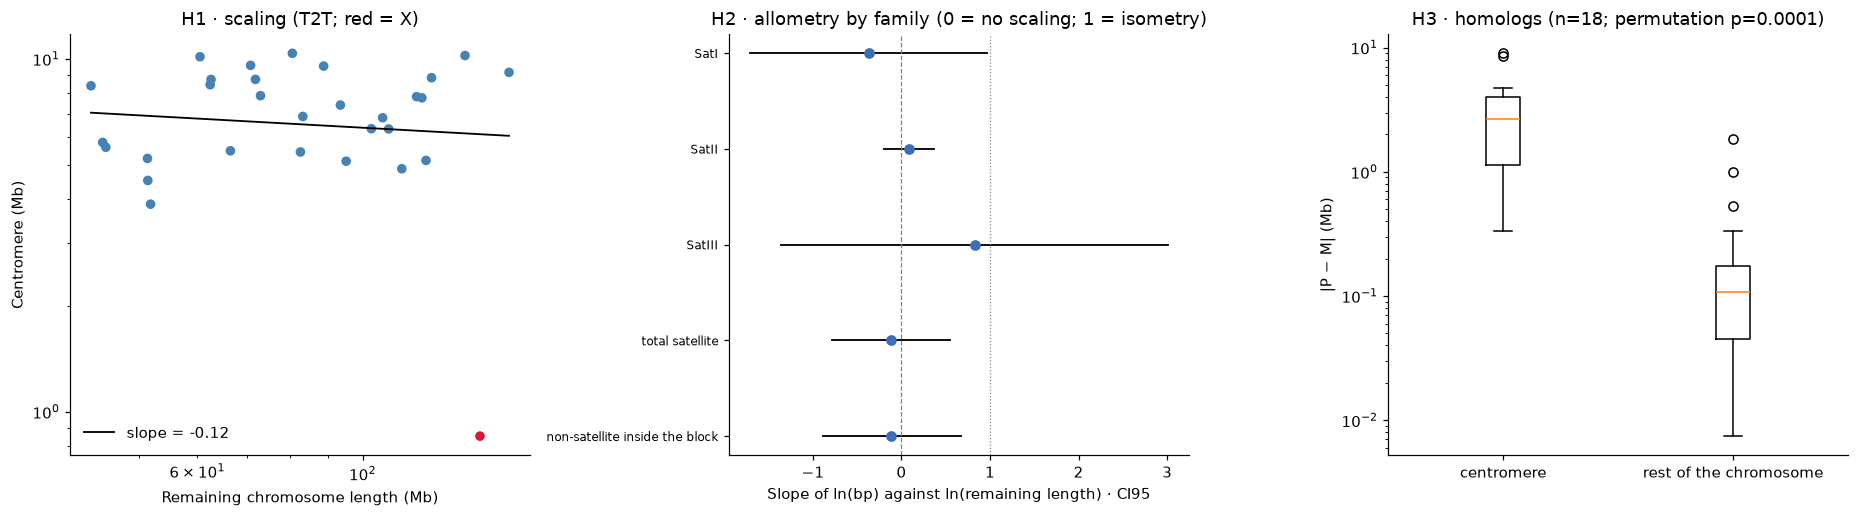

In [9]:
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
nums = lambda s: np.array(re.findall(r'-?\d+\.?\d*', s), float)

# (a) H1
a = ax[0]; a.scatter(D.rest_Mb, D.cen_Mb, c=np.where(D.kind == 'X', 'crimson', 'steelblue'), s=28)
xs = np.linspace(D.lrest.min(), D.lrest.max(), 50); pb = np.polyfit(D.lrest, D.lcen, 1)
a.plot(np.exp(xs), np.exp(np.polyval(pb, xs)), 'k-', lw=1.2, label=f'slope = {pb[0]:.2f}')
a.set_xscale('log'); a.set_yscale('log'); a.set_xlabel('Remaining chromosome length (Mb)'); a.set_ylabel('Centromere (Mb)')
a.set_title('H1 · scaling (T2T; red = X)'); a.legend(frameon=False)

# (b) H2: allometry by family (slope and CI95)
b = ax[1]; yy = np.arange(len(h2_fam))[::-1]
for y_, r in zip(yy, h2_fam.itertuples()):
    lo, hi = nums(r.CI95); b.plot([lo, hi], [y_, y_], 'k-', lw=1.2); b.plot(r.slope, y_, 'o', color='#3b6fb6')
b.axvline(0, color='gray', ls='--', lw=.8); b.axvline(1, color='gray', ls=':', lw=.8)
b.set_yticks(yy); b.set_yticklabels([m.split(' (')[0] for m in h2_fam.model], fontsize=8); b.set_xlabel('Slope of ln(bp) against ln(remaining length) · CI95')
b.set_title('H2 · allometry by family (0 = no scaling; 1 = isometry)')

# (c) H3 on the absolute scale
c = ax[2]; c.boxplot([H.dabs_cen_Mb.abs(), H.dabs_rest_Mb.abs()], showfliers=True); c.set_xticklabels(['centromere', 'rest of the chromosome']); c.set_yscale('log')
c.set_ylabel('|P − M| (Mb)'); c.set_title(f'H3 · homologs (n={len(H)}; permutation p={h3_sens.p_permutation.iloc[1]:.4f})')
plt.tight_layout(); plt.savefig(FIG/'summary.png', dpi=150); plt.show()

## 3.7 · Results summary and export

In [10]:
summary = {
 'n_chromosomes_T2T': int(len(D)),
 'centromere_min_Mb': float(T.cen_len.min()/1e6), 'centromere_max_Mb': float(T.cen_len.max()/1e6), 'shortest_centromere_chromosome': T.loc[T.cen_len.idxmin(), 'chr'],
 'H1_slope': float(h1.slope.iloc[0]), 'H1_CI95': h1.CI95.iloc[0], 'H1_CI95_boot': h1.CI95_boot.iloc[0], 'H1_p_slope_0': float(h1.p_slope_0.iloc[0]),
 'H1_p_interaction_P_M': float(inter.p_interaction.iloc[0]),
 'H1_min_detectable_slope_without_X': float(h1_pot_res.min_detectable_slope_80.iloc[1]), 'H1_min_detectable_slope_with_X': float(h1_pot_res.min_detectable_slope_80.iloc[0]),
 'H2_delta_R2_ratio': float(h2.delta_R2.iloc[0]), 'H2_p_F': h2.p_F_txt.iloc[0], 'H2_delta_R2_without_X': float(h2.delta_R2.iloc[1]),
 'H3_n': int(h3.n_chromosomes.iloc[0]), 'H3_p_permutation_absolute': float(h3.p_permutation_absolute.iloc[0]),
 'H3_median_abs_diff_centromere_Mb': float(h3.median_abs_diff_centromere_Mb.iloc[0]), 'H3_median_abs_diff_rest_Mb': float(h3.median_abs_diff_rest_Mb.iloc[0]),
}
(TAB/'results_summary.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(json.dumps(summary, indent=2, ensure_ascii=False))

{
  "n_chromosomes_T2T": 30,
  "centromere_min_Mb": 0.8528,
  "centromere_max_Mb": 10.3755,
  "shortest_centromere_chromosome": "CHIX",
  "H1_slope": -0.11661433282533343,
  "H1_CI95": "[-0.80, 0.57]",
  "H1_CI95_boot": "[-0.81, 0.38]",
  "H1_p_slope_0": 0.7384080953687185,
  "H1_p_interaction_P_M": 0.6432414100880357,
  "H1_min_detectable_slope_without_X": 0.394399348905976,
  "H1_min_detectable_slope_with_X": 0.6622373892238271,
  "H2_delta_R2_ratio": 0.7327483620539236,
  "H2_p_F": "< 1e-4",
  "H2_delta_R2_without_X": 0.2534105610718247,
  "H3_n": 18,
  "H3_p_permutation_absolute": 5.340576171875e-05,
  "H3_median_abs_diff_centromere_Mb": 2.6712,
  "H3_median_abs_diff_rest_Mb": 0.106861
}


### Generated files (in `data/`)
| File | Content | Origin |
|---|---|---|
| `chromosomes.csv`, `manifest.csv`, `public_runs.csv` | length per chromosome and haplotype; download traceability; PacBio catalogue | real |
| `srf_units.csv`, `satellites_SatI-III.fa`, `srf.fa` | satellite units and their classification | real |
| `satellite_annotation.csv` | SatI–III intervals per chromosome and haplotype | real |
| `centromeres.csv`, **`centromeres_master.csv`** | centromeres per chromosome/haplotype (the master table adds derived columns) | real |
| `qc_*.csv`, `proximal_gaps.csv` | quality controls (orientation, windows, gaps) | real |
| `x_chromosome_check.csv` | evidence on the position of the X centromere | real |
| `H1_scaling.csv`, `H1_influence.csv`, `H1_interaction.csv`, `H1_power*.csv` | scaling, influence, P vs M interaction, power | real |
| `H2_family_allometry.csv`, `H2_composition.csv`, `H2_influence.csv`, `H1H2_chromosome_table_T2T.csv` | satellite composition | real |
| `H3_homologs.csv`, `H3_summary.csv`, `H3_sensitivity.csv` | homologs P vs M | real |
| `breeds_pacbio.csv` | variation between breeds (exploratory) | real (partial) |
| `figures/summary.png`, `results_summary.json` | figure and summary | real |